# Phần A — Kiểu dữ liệu của biến gây nhiễu

Triển khai theo [README](README.md), các hàm được định nghĩa trực tiếp trong cell.
ATE thật = 2.0; beta=(0, 0.5, 0.5), gamma=(0.5, 0.5), sigma=1 — khớp mặc định
`distribution_scenario/distribution.py` (baseline.ipynb cũ dùng tau=3 nên không copy hằng số đó).

**Cỡ mẫu.** Mặc định chạy lưới `N_VALUES = (250, 500, 1000, 2000, 4000, 8000)` cho mọi kịch bản
(`EXTRA_N` dùng để thêm n riêng cho từng kịch bản, hiện để trống). Đổi lưới ở cell tham số hoặc đặt `RA_VARIABLE_N=250,500,1000` trước khi khởi động kernel.
Seed con của mỗi (kịch bản, n) chỉ phụ thuộc `[SEED, mã kịch bản, n]`, nên thêm/bớt n
không làm đổi kết quả của các n đã có (n=500 và n=2000 trùng lần chạy cũ).

**Số lần lặp.** Mặc định **R=200** (chế độ thử nghiệm). Để chạy **R=1000**, đổi R ở cell tham số
hoặc đặt `RA_VARIABLE_REPS=1000`, rồi Run All. Đặt `RA_VARIABLE_RUN_MC=0` để bỏ qua mô phỏng
và chỉ đọc lại CSV đã lưu trong `results/`.

Phạm vi: T0–T6. Mọi PS trong estimator, balance và ESS đều là logistic **ước lượng**, không dùng PS thật.
Các CI là Wald 95%. Kết quả pilot trong README được xem là giả thuyết, không chép làm kết quả.

| Mục | Nội dung |
|---|---|
| 1 | Tham số, thư viện, kiểu biểu đồ |
| 2 | Kịch bản, cách phân tích, kỳ vọng |
| 3–6 | DGP, ma trận thiết kế, estimator, chẩn đoán |
| 7 | Các hàm vẽ biểu đồ |
| 8 | Kiểm tra đơn vị |
| 9 | Khảo sát một mẫu ở vài cỡ n: PS overlap, balance |
| 10–11 | Monte Carlo trên lưới n, tóm tắt từ CSV |
| 12 | Tổng quan bias và coverage theo n |
| 13 | Kỳ vọng → kết quả → giải thích cho từng kịch bản |
| 14 | Kết luận |

## 1. Tham số và thư viện
Môi trường cần numpy, pandas, scipy, statsmodels, matplotlib, IPython và Jupyter, giống các notebook mô phỏng hiện có.

In [1]:
import os
import csv
import json
import time
import warnings
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
import scipy
from scipy.special import expit
from scipy.stats import norm
import statsmodels
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
# Hiển thị và lưu hình ngay trong notebook khi Run All.
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator, NullLocator
from IPython.display import display, Markdown

In [2]:
# --- Mô hình sinh dữ liệu ---
TAU = 2.0
BETA = (0.0, 0.5, 0.5)
GAMMA = (0.5, 0.5)
SIGMA = 1.0
N_REF = 200_000          # mẫu tham chiếu để hiệu chỉnh gamma0

# --- Lưới cỡ mẫu ---
N_VALUES = tuple(sorted(int(v) for v in
                        os.environ.get("RA_VARIABLE_N", "250,500,1000,2000,4000,8000").split(",")))
EXTRA_N = {}  # n thêm riêng cho từng kịch bản, ví dụ {"T6": (16000,)}
INSPECT_N = tuple(N_VALUES[i] for i in sorted({0, len(N_VALUES)//2, len(N_VALUES)-1}))

# --- Monte Carlo ---
R_FULL = 1000
R = int(os.environ.get("RA_VARIABLE_REPS", "1000"))
RUN_MC = os.environ.get("RA_VARIABLE_RUN_MC", "1") != "0"
SEED = 20261021
METHODS = ("Naive", "OLS", "IPTW", "AIPW")
ADJUSTED = ("OLS", "IPTW", "AIPW")
Z95 = norm.ppf(0.975)
if R < 2:
    raise ValueError("Monte Carlo cần R >= 2 để tính SD và MC SE.")
if min(N_VALUES) < 4:
    raise ValueError("Mọi n phải >= 4.")

# Chạy từ thư mục notebook, gốc dự án, hoặc gốc workspace.
RESULT_DIR = next((p for p in (Path.cwd(), Path.cwd() / "scenario/variable_scenario",
                              Path.cwd() / "ra_causal/scenario/variable_scenario")
                   if (p / "variable_type.ipynb").exists()), None)
if RESULT_DIR is None:
    raise FileNotFoundError("Hãy chạy kernel từ variable_scenario, ra_causal hoặc Seminar.")
RESULT_DIR = RESULT_DIR / "results"
FIG_DIR = RESULT_DIR / "figures_A"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)
print(f"R={R}; n={N_VALUES}; thêm {EXTRA_N}; khảo sát một mẫu ở n={INSPECT_N}")
print(f"tau={TAU}; chạy MC={RUN_MC}; results={RESULT_DIR}")

R=1000; n=(250, 500, 1000, 2000, 4000, 8000); thêm {}; khảo sát một mẫu ở n=(250, 2000, 8000)
tau=2.0; chạy MC=True; results=/home/doan/Seminar/ra_causal/scenario/variable_scenario/results


In [3]:
# Kiểu biểu đồ dùng chung. Màu theo vai trò, cố định cho mọi hình:
# phương pháp (Naive xám làm mốc tham chiếu), nhóm điều trị, và thang phân kỳ đỏ–xám–xanh.
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8986"
GRID, SHADE = "#e9e8e4", "#f0efec"
METHOD_STYLE = {
    "Naive": dict(color="#7a7974", marker="x"),
    "OLS":   dict(color="#2a78d6", marker="o"),
    "IPTW":  dict(color="#eb6834", marker="s"),
    "AIPW":  dict(color="#1baf7a", marker="^"),
}
TREAT_COLORS = {1: "#2a78d6", 0: "#eb6834"}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
BINNED_RAMP = {2: "#86b6ef", 3: "#5598e7", 5: "#256abf", 10: "#104281"}
DIVERGING = LinearSegmentedColormap.from_list("red_gray_blue", ["#e34948", SHADE, "#2a78d6"])
# Coverage: dưới 0.95 là vấn đề (đỏ đậm dần); trên 0.95 chỉ là thận trọng (xanh nhạt).
COVERAGE_CMAP = LinearSegmentedColormap.from_list("coverage", ["#e34948", SHADE, "#9ec5f4"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlesize": 10, "axes.titleweight": "semibold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "legend.frameon": False, "lines.linewidth": 1.8, "lines.markersize": 5.5,
})


def analysis_style(scenario, analysis):
    """T6: hai mốc tham chiếu + dải xanh đậm dần theo số nhóm; kịch bản khác: màu phân loại."""
    if scenario == "T6":
        if analysis == "continuous":
            return dict(color=INK, ls="-", marker="o")
        if analysis == "omit_X2":
            return dict(color=INK_3, ls="--", marker="x")
        return dict(color=BINNED_RAMP[int(analysis.split("_")[1])], ls="-", marker="s")
    i = list(ANALYSES[scenario]).index(analysis)
    return dict(color=CATEGORICAL[i], ls="-", marker="os^Dv"[i])


def style_n_axis(ax, ns):
    """Trục n dạng log, vạch đúng tại các n đã chạy."""
    ax.set_xscale("log")
    ax.set_xticks(list(ns))
    ax.set_xticklabels([f"{n:,}" for n in ns])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(min(ns) / 1.25, max(ns) * 1.25)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

## 2. Kịch bản, cách phân tích và kỳ vọng
`SCENARIOS` mô tả DGP của X2; `ANALYSES` là các cách mã hóa X2 khi điều chỉnh;
`EXPECTATIONS` gom kỳ vọng (gồm cả kỳ vọng theo n) và giải thích để mục 9 và 13 dùng chung, không lặp chữ.

In [4]:
SCENARIOS = {
    "T0": dict(x2="continuous"),
    "T1": dict(x2="categorical", probs=[.5, .5], g=[0, 1], h=[0, 1]),
    "T2": dict(x2="categorical", probs=[.9, .1], g=[0, 1], h=[0, 1]),
    "T3a": dict(x2="categorical", probs=[.1, .2, .4, .2, .1],
                g=[0, 1, 2, 3, 4], h=[0, 1, 2, 3, 4]),
    "T3b": dict(x2="categorical", probs=[.1, .2, .4, .2, .1],
                g=[0, 1, 1, 0, -1], h=[0, 1, 1, 0, -1]),
    "T4": dict(x2="categorical", probs=[.4, .3, .2, .1],
               g=[0, 1, -1, .5], h=[0, .5, -.5, 1.5]),
    # T5 cố ý tăng confounding/giảm overlap: g không chuẩn hóa Var=0.25.
    "T5": dict(x2="rare_overlap", probs=[.45, .45, .1], h=[-1, 0, 1]),
    "T6": dict(x2="continuous"),
}
ANALYSES = {
    "T0": {"continuous": {"X1": "continuous", "X2": "continuous"}},
    "T1": {"binary": {"X1": "continuous", "X2": "integer"}},
    "T2": {"binary": {"X1": "continuous", "X2": "integer"}},
    "T3a": {a: {"X1": "continuous", "X2": a} for a in ("integer", "dummy")},
    "T3b": {a: {"X1": "continuous", "X2": a} for a in ("integer", "dummy")},
    "T4": {a: {"X1": "continuous", "X2": a} for a in ("dummy", "label")},
    "T5": {"dummy": {"X1": "continuous", "X2": "dummy"}},
    "T6": {"continuous": {"X1": "continuous", "X2": "continuous"},
           "omit_X2": {"X1": "continuous"},
           **{f"binned_{k}": {"X1": "continuous", "X2": f"binned_{k}"}
              for k in (2, 3, 5, 10)}},
}


EXPECTATIONS = {
    "T0": dict(expect="Các estimator điều chỉnh gần không chệch, SE/SD gần 1, coverage gần 0.95; Naive chệch.",
               by_n="Bias ≈ 0 ở mọi n; RMSE giảm theo 1/√n; coverage ổn định quanh 0.95.",
               explain="DGP và mô hình điều chỉnh đều tuyến tính đúng dạng."),
    "T1": dict(expect="Nhị phân cân bằng gần baseline khi giữ Var đóng góp = 0.25.",
               by_n="Giống T0: RMSE giảm theo 1/√n, coverage không phụ thuộc n.",
               explain="Hiệu ứng theo mức được tâm hóa và chuẩn hóa; mã 0/1 biểu diễn đúng DGP."),
    "T2": dict(expect="Mức hiếm làm các ô nhỏ và có thể tăng bất ổn IPTW/AIPW.",
               by_n="Ô nhỏ ở n nhỏ làm SE/SD và coverage của IPTW/AIPW lệch nhiều hơn; khác biệt thu hẹp khi n tăng.",
               explain="Cần đọc đồng thời SE/SD, coverage và số lần có ô rỗng; không suy luận chỉ từ bias."),
    "T3a": dict(expect="Integer và dummy cùng gần không chệch; dummy có thể mất một ít hiệu quả.",
                by_n="Cả hai mã hóa có RMSE giảm theo 1/√n; chênh lệch hiệu quả của dummy nhỏ.",
                explain="Hiệu ứng tuyến tính theo mức nên integer đã đủ; dummy dùng thêm ba tham số."),
    "T3b": dict(expect="Integer chệch; dummy gần không chệch.",
                by_n="Bias của integer không giảm theo n, CI hẹp lại nên coverage giảm khi n tăng; dummy giữ coverage gần 0.95.",
                explain="Cả PS và outcome dùng integer đều sai dạng; double robustness không cứu khi cả hai sai."),
    "T4": dict(expect="Label encoding sai dạng so với dummy; dấu và độ lớn bias phụ thuộc g/h.",
               by_n="Như T3b: bias của label giữ nguyên theo n nên coverage giảm khi n tăng.",
               explain="Hiệu ứng PS và outcome khác nhau; thứ tự nhãn không biểu diễn vector hiệu ứng theo mức."),
    "T5": dict(expect="Trọng số cực đoan, ESS thấp, có thể có ô control rỗng ở mức hiếm.",
               by_n="n nhỏ: mức hiếm có rất ít control nên nhiều rep có ô rỗng hoặc fit thất bại; "
                    "tăng n giảm tỉ lệ lỗi nhưng ESS/n vẫn thấp vì overlap kém là đặc tính của DGP.",
               explain="T5 cố ý phá quy tắc giữ Var(g)=0.25 để tạo marginal e≈0.98 trong mức hiếm. "
                       "Fit thất bại vẫn lưu một dòng; chỉ số chất lượng tính trên các lần thành công. "
                       "Vì vậy ở n nhỏ, ESS/n và trọng số lớn nhất chỉ phản ánh các rep fit được PS "
                       "(có chọn lọc), nên trông tốt hơn n lớn; cần đọc cùng tỉ lệ lỗi fit."),
    "T6": dict(expect="Bias còn sót giảm khi tăng số nhóm; tăng n không xóa bias do rời rạc hóa.",
               by_n="Bias của các cách chia nhóm gần như không đổi theo n, nên coverage giảm dần khi n tăng, rõ nhất khi ít nhóm.",
               explain="DGP dùng X2 liên tục, analysis dùng nhóm phân vị. CI hẹp dần khi n tăng khiến coverage giảm "
                       "nếu bias còn sót. So sánh hai mốc continuous và omit_X2."),
}


def n_grid(scenario, n_values=N_VALUES):
    """Các n chạy cho một kịch bản: lưới chung cộng phần thêm riêng."""
    return tuple(sorted(set(n_values) | set(EXTRA_N.get(scenario, ()))))


def show_expectation(scenario):
    e = EXPECTATIONS[scenario]
    display(Markdown(f"**Kỳ vọng:** {e['expect']}  \n**Theo n:** {e['by_n']}"))

## 3. Sinh dữ liệu
Hiệu chỉnh gamma0 trên mẫu tham chiếu 200.000 quan sát độc lập cho từng kịch bản. Cache chỉ tránh tính lại cùng một DGP; không hiệu chỉnh theo từng mẫu Monte Carlo.

In [5]:
def standardize_effect(raw, probs):
    """Tâm hóa theo xác suất tổng thể; Var đóng góp = 0.25."""
    raw, p = np.asarray(raw, float), np.asarray(probs, float)
    centered = raw - p @ raw
    return 0.5 * centered / np.sqrt(p @ centered**2)


def _draw_covariates(n, scenario, rng):
    cfg = SCENARIOS[scenario]
    x1 = rng.normal(size=n)
    if cfg["x2"] == "continuous":
        x2 = rng.normal(size=n)
        g2, h2 = GAMMA[1] * x2, BETA[2] * x2
    else:
        x2 = rng.choice(len(cfg["probs"]), size=n, p=cfg["probs"])
        h2 = standardize_effect(cfg["h"], cfg["probs"])[x2]
        g2 = (standardize_effect(cfg["g"], cfg["probs"])[x2]
              if cfg["x2"] != "rare_overlap" else np.zeros(n))
    data = {"X1": x1, "X2": x2}
    lin = GAMMA[0] * x1 + g2
    mu0 = BETA[0] + BETA[1] * x1 + h2
    if cfg.get("has_x3", False):
        rho = cfg.get("rho", 0.)
        x3 = rho * x1 + np.sqrt(1 - rho**2) * rng.normal(size=n)
        data["X3"] = x3
        lin = lin + cfg["g3"] * x3
        mu0 = mu0 + cfg["b3"] * x3
    return data, lin, mu0


def _bisect_intercept(lin, target):
    lo, hi = -50., 50.
    for _ in range(60):
        mid = (lo + hi) / 2
        if expit(mid + lin).mean() < target:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


@lru_cache(maxsize=None)
def _calibrate_gamma0(scenario):
    """Mẫu tham chiếu độc lập, cố định; hiệu chỉnh một lần cho từng DGP."""
    data, lin, _ = _draw_covariates(N_REF, scenario, np.random.default_rng(12345))
    cfg = SCENARIOS[scenario]
    if cfg["x2"] == "rare_overlap":
        # Hiệu chỉnh marginal e trong mức hiếm = .98 và treated toàn mẫu = .50.
        rare = data["X2"] == 2
        p_rare = rare.mean()
        target_common = (0.5 - p_rare * 0.98) / (1 - p_rare)
        gamma0 = _bisect_intercept(lin[~rare], target_common)
        rare_intercept = _bisect_intercept(lin[rare], .98)
        return gamma0, rare_intercept - gamma0
    return _bisect_intercept(lin, .5), 0.


def simulate(n, scenario, seed):
    """Seed con được truyền trực tiếp vào RNG; không dùng RNG toàn cục."""
    if scenario not in SCENARIOS or n < 4:
        raise ValueError("Kịch bản không tồn tại hoặc n < 4.")
    rng = np.random.default_rng(seed)
    data, lin, mu0 = _draw_covariates(n, scenario, rng)
    gamma0, rare_gamma = _calibrate_gamma0(scenario)
    if SCENARIOS[scenario]["x2"] == "rare_overlap":
        lin = lin + rare_gamma * (data["X2"] == 2)
    ps_true = expit(gamma0 + lin)
    a = rng.binomial(1, ps_true)
    eps = rng.normal(0, SIGMA, n)
    df = pd.DataFrame({**data, "A": a, "Y": mu0 + TAU * a + eps})
    # Truth giữ riêng; estimator/diagnostics chỉ nhận dữ liệu quan sát.
    truth = pd.DataFrame({"ps_true": ps_true, "mu0": mu0,
                          "Y0": mu0 + eps, "Y1": mu0 + eps + TAU})
    df.attrs.update(scenario=scenario, gamma0=gamma0, rare_gamma=rare_gamma)
    return df, truth

## 4. Ma trận thiết kế
Cùng design có chặn được dùng cho OLS, PS và outcome của AIPW. Dummy giữ đủ mức theo cấu hình. Với T6, ngưỡng chia nhóm là phân vị tổng thể N(0,1), giúp so sánh các cỡ mẫu trên cùng phép đo.

In [6]:
def make_design(df, spec):
    """Có chặn; dummy có đủ mức theo DGP ngay cả khi mẫu vắng một mức.

    Với T6, dùng ngưỡng phân vị N(0,1) cố định (không ước lượng lại theo mẫu).
    Các biến vắng trong spec được bỏ khỏi mọi mô hình.
    """
    out = pd.DataFrame({"const": np.ones(len(df))}, index=df.index)
    cfg = SCENARIOS[df.attrs["scenario"]]
    for col, encoding in spec.items():
        if encoding in ("continuous", "integer", "label"):
            out[col] = df[col].astype(float)
        elif encoding == "dummy" or encoding.startswith("binned_"):
            if encoding == "dummy":
                levels = range(len(cfg["probs"]))
                values = df[col]
            else:
                k = int(encoding.split("_")[1])
                levels = range(k)
                values = np.digitize(df[col], norm.ppf(np.arange(1, k) / k))
            categories = pd.Series(pd.Categorical(values, categories=levels), index=df.index)
            dummies = pd.get_dummies(categories, prefix=col, drop_first=True, dtype=float)
            out = pd.concat([out, dummies], axis=1)
        else:
            raise ValueError(f"Mã hóa không hỗ trợ: {encoding}")
    return out


def balance_design(df, spec):
    """Balance định tính luôn kiểm tra mọi dummy, kể cả khi fit bằng integer/label."""
    full_spec = dict(spec)
    cfg = SCENARIOS[df.attrs["scenario"]]
    if "X2" in spec and cfg["x2"] != "continuous":
        full_spec["X2"] = "dummy"
    out = make_design(df, full_spec).drop(columns="const")
    if "X2" in spec and cfg["x2"] != "continuous":
        # Thêm dummy mức tham chiếu để không bỏ mất mất cân bằng ở mức này.
        out["X2_0"] = (df.X2 == 0).astype(float)
    elif spec.get("X2", "").startswith("binned_"):
        k = int(spec["X2"].split("_")[1])
        out["X2_0"] = (np.digitize(df.X2, norm.ppf(np.arange(1, k) / k)) == 0).astype(float)
    return out

## 5. Bốn estimator và SE
Naive: Welch; OLS: HC1; IPTW Hájek: IF hiệu chỉnh ước lượng logistic; AIPW: SD của pseudo-outcome / sqrt(n). Logistic không penalize hoặc clip. Fit không xác định/hội tụ được ghi status và NaN, vẫn giữ số lần lặp yêu cầu.

In [7]:
class FitFailure(ValueError):
    pass


def _check_rank(design):
    if np.linalg.matrix_rank(design) < design.shape[1]:
        raise FitFailure("rank_deficient")


def fit_propensity(A, design):
    x = np.asarray(design, float)
    _check_rank(x)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        fit = sm.Logit(A, x).fit(disp=False, maxiter=100)
    if any(issubclass(w.category, PerfectSeparationWarning) for w in caught):
        raise FitFailure("perfect_separation")
    if not fit.mle_retvals.get("converged", False):
        raise FitFailure("ps_not_converged")
    e = np.asarray(fit.predict(x))
    if not np.isfinite(e).all() or np.any((e <= 0) | (e >= 1)):
        raise FitFailure("ps_at_boundary")
    # Không clip hay regularize âm thầm: T5 cần giữ trọng số cực đoan thật sự.
    return e


def est_naive(Y, A, design):
    y1, y0 = Y[A == 1], Y[A == 0]
    if min(len(y1), len(y0)) < 2:
        raise FitFailure("treatment_group_too_small")
    return y1.mean() - y0.mean(), np.sqrt(y1.var(ddof=1)/len(y1) + y0.var(ddof=1)/len(y0))


def est_ols(Y, A, design):
    x = np.column_stack([np.asarray(design), A])
    _check_rank(x)
    fit = sm.OLS(Y, x).fit(cov_type="HC1")
    return fit.params[-1], fit.bse[-1]


def est_iptw(Y, A, design, e_hat=None):
    """Hájek, IF có hiệu chỉnh score/logistic như est_iptw trong baseline.ipynb."""
    x = np.asarray(design, float)
    e = fit_propensity(A, x) if e_hat is None else e_hat
    w1, w0 = A/e, (1-A)/(1-e)
    mu1, mu0 = (w1 @ Y)/w1.sum(), (w0 @ Y)/w0.sum()
    psi = w1*(Y-mu1)/w1.mean() - w0*(Y-mu0)/w0.mean()
    a1 = x.T @ (-w1*(Y-mu1)*(1-e)) / len(Y) / w1.mean()
    a0 = x.T @ (w0*(Y-mu0)*e) / len(Y) / w0.mean()
    information = (x * (e*(1-e))[:, None]).T @ x / len(Y)
    score = x * (A-e)[:, None]
    influence = psi + score @ np.linalg.solve(information, a1-a0)
    return mu1-mu0, influence.std(ddof=1)/np.sqrt(len(Y))


def est_aipw(Y, A, design, e_hat=None):
    x = np.asarray(design, float)
    e = fit_propensity(A, x) if e_hat is None else e_hat
    predictions = {}
    for t in (0, 1):
        xt = x[A == t]
        _check_rank(xt)  # Ô rỗng: không dùng pseudoinverse để giả vờ hệ số xác định.
        if len(xt) <= x.shape[1]:
            raise FitFailure("outcome_group_too_small")
        b = np.linalg.lstsq(xt, Y[A == t], rcond=None)[0]
        predictions[t] = x @ b
    m1, m0 = predictions[1], predictions[0]
    psi = m1-m0 + A*(Y-m1)/e - (1-A)*(Y-m0)/(1-e)
    return psi.mean(), psi.std(ddof=1)/np.sqrt(len(Y))


def estimate_all(df, design):
    Y, A = df.Y.to_numpy(), df.A.to_numpy()
    estimates, status = {}, {}
    failure_types = (FitFailure, np.linalg.LinAlgError, ValueError,
                     sm.tools.sm_exceptions.PerfectSeparationError)
    def record(method, call):
        try:
            value = tuple(float(v) for v in call())
            if not np.isfinite(value).all() or value[1] < 0:
                raise FitFailure("nonfinite_estimate_or_se")
            estimates[method], status[method] = value, "ok"
        except failure_types as exc:
            estimates[method], status[method] = (np.nan, np.nan), str(exc)
    record("Naive", lambda: est_naive(Y, A, design))
    record("OLS", lambda: est_ols(Y, A, design))
    try:
        e = fit_propensity(A, design)
        ps_status = "ok"
    except failure_types as exc:
        e, ps_status = None, str(exc)
    if e is None:
        for method in ("IPTW", "AIPW"):
            estimates[method], status[method] = (np.nan, np.nan), ps_status
    else:
        record("IPTW", lambda: est_iptw(Y, A, design, e))
        record("AIPW", lambda: est_aipw(Y, A, design, e))
    return estimates, e, status, ps_status

## 6. Chẩn đoán: ô đếm, SMD, PS và ESS
SMD nhị phân/dummy dùng mẫu số từ tỷ lệ từng nhóm; biến liên tục dùng mẫu số trước weighting. Không tính VR cho dummy. Balance định tính kiểm tra cả mức tham chiếu và mọi dummy, kể cả analysis dùng integer/label.

In [8]:
def ipw_weights(A, e):
    """Trọng số IPW cho ATE: 1/e với treated, 1/(1-e) với control."""
    return A/e + (1-A)/(1-e)


def ess_ratio(w):
    """ESS Kish chia n."""
    return w.sum()**2/(w @ w)/len(w)


def cell_counts(df, spec):
    cfg = SCENARIOS[df.attrs["scenario"]]
    if cfg["x2"] != "continuous":
        values, levels = df.X2, range(len(cfg["probs"]))
    elif spec.get("X2", "").startswith("binned_"):
        k = int(spec["X2"].split("_")[1])
        values, levels = np.digitize(df.X2, norm.ppf(np.arange(1, k)/k)), range(k)
    else:
        return pd.DataFrame()
    return pd.crosstab(df.A, pd.Series(np.asarray(values), index=df.index, name="X2_level")) \
             .reindex(index=[0, 1], columns=list(levels), fill_value=0)


def smd_table(covariates, A, weights=None):
    w = np.ones(len(A)) if weights is None else np.asarray(weights)
    rows = []
    for col in covariates:
        x = covariates[col].to_numpy(float)
        m1 = np.average(x[A == 1], weights=w[A == 1])
        m0 = np.average(x[A == 0], weights=w[A == 0])
        binary = np.isin(x, [0., 1.]).all()
        if binary:
            denom = np.sqrt((m1*(1-m1) + m0*(1-m0))/2)
        else:
            # Mẫu số trước weighting, giống nhau trước/sau với biến liên tục.
            denom = np.sqrt((x[A == 1].var(ddof=1)+x[A == 0].var(ddof=1))/2)
        smd = (m1-m0)/denom if denom > 0 else (0. if m1 == m0 else np.inf)
        rows.append({"variable": col, "kind": "binary" if binary else "continuous", "smd": smd})
    return pd.DataFrame(rows).set_index("variable")


def diagnostics(df, spec, e):
    A = df.A.to_numpy()
    counts = cell_counts(df, spec)
    covs = balance_design(df, spec)
    before = smd_table(covs, A)
    result = {"treated_rate": A.mean(), "empty_cells": int((counts == 0).sum().sum()),
              "has_empty_cell": bool((counts == 0).any().any()) if not counts.empty else False,
              "min_cell_count": counts.to_numpy().min() if not counts.empty else np.nan,
              "cell_counts": counts.to_json() if not counts.empty else "{}",
              "max_abs_smd_before": before.smd.abs().max(),
              "e_min": np.nan, "e_max": np.nan, "e_outside": np.nan,
              "max_weight": np.nan, "ess_ratio": np.nan,
              "ess_treated_ratio": np.nan, "ess_control_ratio": np.nan,
              "max_abs_smd_after": np.nan, "x3_smd_after": np.nan,
              "x2_continuous_smd_after": np.nan}
    if e is not None:
        w = ipw_weights(A, e)
        result.update(e_min=e.min(), e_max=e.max(),
                      e_outside=np.mean((e < .01) | (e > .99)), max_weight=w.max(),
                      ess_ratio=ess_ratio(w),
                      max_abs_smd_after=smd_table(covs, A, w).smd.abs().max())
        for t, name in ((1, "treated"), (0, "control")):
            result[f"ess_{name}_ratio"] = ess_ratio(w[A == t])
        # Chẩn đoán mô phỏng: biến bị bỏ chỉ người mô phỏng mới quan sát được.
        if "X3" in df:
            result["x3_smd_after"] = smd_table(df[["X3"]], A, w).smd.iloc[0]
        if df.attrs["scenario"] == "T6":
            result["x2_continuous_smd_after"] = smd_table(df[["X2"]], A, w).smd.iloc[0]
    return result


def balance_table(df, spec, e):
    """SMD từng cột balance trước và sau IPW (NaN nếu PS lỗi)."""
    A = df.A.to_numpy()
    covs = balance_design(df, spec)
    table = smd_table(covs, A).rename(columns={"smd": "smd_before"})
    table["smd_after"] = smd_table(covs, A, ipw_weights(A, e)).smd if e is not None else np.nan
    return table

## 7. Hàm vẽ biểu đồ
Mọi hình dùng cùng màu cho cùng phương pháp và trục n dạng log (vạch tại đúng các n đã chạy).
Hình được lưu vào `results/figures_A/`.

| Hàm | Dùng ở | Đọc gì |
|---|---|---|
| `plot_ps_overlap` | Mục 9 | Phân phối PS ước lượng dạng gương: A=1 phía trên, A=0 phía dưới; vùng xám là e<0.05 hoặc e>0.95 |
| `plot_love` | Mục 9 | \|SMD\| từng biến trước/sau IPW, ngưỡng 0.1 |
| `plot_overview_heatmap` | Mục 12 | Bias hoặc coverage của mọi kịch bản × n trong một hình |
| `plot_metrics_vs_n` | Mục 13 | Bias ± 1.96 MC SE, RMSE, coverage, SE/SD theo n |
| `plot_estimate_distribution` | Mục 13 | Phân phối ước lượng qua các rep, theo n và phương pháp |
| `plot_diagnostics_vs_n` | Mục 13 | ESS/n, trọng số lớn nhất, SMD sau IPW, ô rỗng, lỗi PS theo n |

In [9]:
def plot_ps_overlap(scenario, fits, n_values, analyses):
    """fits[(n, analysis)] = (A, e, ps_status). Hàng = n, cột = cách phân tích."""
    nr, nc = len(n_values), len(analyses)
    fig, axes = plt.subplots(nr, nc, figsize=(min(max(2.6*nc, 5.5) + 0.8, 16), 1.9*nr + 1.1),
                             squeeze=False, sharex=True, layout="constrained")
    bins = np.linspace(0, 1, 41)
    for i, n in enumerate(n_values):
        for j, analysis in enumerate(analyses):
            ax = axes[i, j]
            A, e, ps_status = fits[n, analysis]
            ax.axvspan(0, .05, color=SHADE, lw=0, zorder=0)
            ax.axvspan(.95, 1, color=SHADE, lw=0, zorder=0)
            ax.grid(False)
            if e is None:
                ax.text(.5, .5, f"PS lỗi\n{ps_status}", ha="center", va="center",
                        transform=ax.transAxes, color=INK_2)
                ax.set_yticks([])
            else:
                for t, sign in ((1, 1), (0, -1)):
                    h, _ = np.histogram(e[A == t], bins=bins, density=True)
                    ax.bar(bins[:-1], sign*h, width=np.diff(bins), align="edge",
                           color=TREAT_COLORS[t], edgecolor="white", linewidth=.4)
                ax.axhline(0, color=INK_2, lw=.8)
                top = np.abs(ax.get_ylim()).max()
                ax.set_ylim(-top, top)
                ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{abs(v):g}"))
                w = ipw_weights(A, e)
                ax.text(.03, .97, f"ESS/n={ess_ratio(w):.0%}\nmax w={w.max():.0f}",
                        transform=ax.transAxes, va="top", fontsize=7.5, color=INK_2)
            ax.set_xlim(0, 1)
            if i == 0:
                ax.set_title(analysis)
            if j == 0:
                ax.set_ylabel(f"n={n:,}\nmật độ")
            if i == nr - 1:
                ax.set_xlabel("PS ước lượng ê(X)")
    handles = [Patch(color=TREAT_COLORS[1], label="A=1 (phía trên)"),
               Patch(color=TREAT_COLORS[0], label="A=0 (phía dưới)"),
               Patch(color=SHADE, label="ê<0.05 hoặc ê>0.95")]
    fig.legend(handles=handles, loc="outside lower center", ncol=3)
    fig.suptitle(f"{scenario} — overlap của PS ước lượng theo n", x=0.01, ha="left")
    return fig


def plot_love(scenario, tables, n):
    """tables[analysis] = balance_table(...). Một panel/cách phân tích."""
    nc = len(tables)
    height = max(len(t) for t in tables.values())
    fig, axes = plt.subplots(1, nc, figsize=(min(max(2.6*nc, 5.5) + 0.8, 16), .32*height + 1.6),
                             squeeze=False, layout="constrained")
    xmax = max(np.nanmax(np.abs(t[["smd_before", "smd_after"]].to_numpy(float)))
               for t in tables.values())
    for ax, (analysis, table) in zip(axes[0], tables.items()):
        y = np.arange(len(table))[::-1]
        ax.hlines(y, table.smd_after.abs(), table.smd_before.abs(), color=GRID, lw=2, zorder=1)
        ax.scatter(table.smd_before.abs(), y, s=36, facecolor="white", edgecolor=INK_3,
                   lw=1.4, zorder=2)
        ax.scatter(table.smd_after.abs(), y, s=36, color=METHOD_STYLE["IPTW"]["color"], zorder=3)
        ax.axvline(.1, color=INK_2, ls=":", lw=1)
        ax.set_yticks(y)
        ax.set_yticklabels(table.index)
        ax.set_xlim(0, max(.15, xmax*1.1))
        ax.set_title(analysis)
        ax.set_xlabel("|SMD|")
        ax.grid(axis="y", visible=False)
    handles = [Line2D([], [], ls="", marker="o", mfc="white", mec=INK_3, label="trước IPW"),
               Line2D([], [], ls="", marker="o", color=METHOD_STYLE["IPTW"]["color"], label="sau IPW"),
               Line2D([], [], ls=":", color=INK_2, label="ngưỡng 0.1")]
    fig.legend(handles=handles, loc="outside lower center", ncol=3)
    fig.suptitle(f"{scenario} — balance trước/sau IPW, n={n:,}", x=0.01, ha="left")
    return fig

In [10]:
def _scenario_labels(table):
    return [f"{s} · {a}" for s, a in table.index]


def plot_overview_heatmap(summary, value, methods=ADJUSTED):
    """Một panel/phương pháp; hàng = kịch bản·phân tích, cột = n. Ô trống: n không chạy."""
    if value == "coverage":
        norm_ = TwoSlopeNorm(vmin=0, vcenter=.95, vmax=1)
        cmap, fmt, title = COVERAGE_CMAP, "{:.2f}", "Coverage CI 95% (đỏ = thấp hơn 0.95)"
    else:
        lim = summary.loc[summary.method.isin(methods), "bias"].abs().max()
        norm_ = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
        cmap, fmt, title = DIVERGING, "{:+.3f}", "Bias (đỏ = âm, xanh = dương)"
    order = [(s, a) for s in SCENARIOS for a in ANALYSES[s]]
    ns = sorted(summary.n.unique())
    fig, axes = plt.subplots(1, len(methods), figsize=(3.4*len(methods) + 1.6, .3*len(order) + 1.6),
                             sharey=True, layout="constrained")
    for k, (ax, method) in enumerate(zip(np.atleast_1d(axes), methods)):
        table = (summary[summary.method.eq(method)]
                 .pivot_table(index=["scenario", "analysis"], columns="n", values=value)
                 .reindex(index=order, columns=ns))
        data = table.to_numpy(float)
        image = ax.imshow(np.ma.masked_invalid(data), cmap=cmap, norm=norm_, aspect="auto")
        for (r, c), v in np.ndenumerate(data):
            if np.isfinite(v):
                red, green, blue, _ = cmap(norm_(v))
                dark = .2126*red + .7152*green + .0722*blue < .5
                ax.text(c, r, fmt.format(v), ha="center", va="center", fontsize=7,
                        color="white" if dark else INK)
        ax.set_xticks(range(len(ns)))
        ax.set_xticklabels([f"{n:,}" for n in ns], rotation=45)
        ax.set_yticks(range(len(order)))
        ax.set_yticklabels(_scenario_labels(table))
        ax.set_title(method)
        ax.set_xlabel("n")
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        # Vạch ngăn giữa các kịch bản.
        bounds = np.cumsum([len(ANALYSES[s]) for s in SCENARIOS])[:-1]
        for b in bounds:
            ax.axhline(b - .5, color="white", lw=2)
    fig.colorbar(image, ax=axes, shrink=.6, pad=.02)
    fig.suptitle(title, x=0.01, ha="left")
    return fig

In [11]:
def plot_metrics_vs_n(summary_s, scenario, methods=ADJUSTED, n_reps=R):
    """Hàng = cách phân tích, cột = bias / RMSE / coverage / SE÷SD. Naive xem ở bảng và hình phân phối."""
    analyses = list(ANALYSES[scenario])
    ns = n_grid(scenario)
    cols = ("Bias ± 1.96·MC SE", "RMSE (log)", "Coverage CI 95%", "SE / SD thực nghiệm")
    fig, axes = plt.subplots(len(analyses), 4, figsize=(13, 2.2*len(analyses) + 1.1),
                             squeeze=False, sharex=True, layout="constrained")
    band = Z95*np.sqrt(.95*.05/n_reps)
    for i, analysis in enumerate(analyses):
        rows = summary_s[summary_s.analysis.eq(analysis)]
        ax_bias, ax_rmse, ax_cov, ax_ratio = axes[i]
        ax_bias.axhline(0, color=INK_2, lw=.8)
        ax_cov.axhspan(.95 - band, .95 + band, color=SHADE, lw=0)
        ax_cov.axhline(.95, color=INK_2, lw=.8, ls="--")
        ax_ratio.axhline(1, color=INK_2, lw=.8, ls="--")
        for method in methods:
            g = rows[rows.method.eq(method)].sort_values("n")
            st = METHOD_STYLE[method]
            ax_bias.errorbar(g.n, g.bias, yerr=Z95*g.mc_se_bias, capsize=2, **st)
            ax_rmse.plot(g.n, g.rmse, **st)
            ax_cov.plot(g.n, g.coverage, **st)
            ax_ratio.plot(g.n, g.se_sd_ratio, **st)
        # Đường tham chiếu ∝ 1/√n, neo tại RMSE nhỏ nhất ở n nhỏ nhất.
        first = rows[rows.method.isin(methods) & rows.n.eq(min(ns))].rmse.min()
        if np.isfinite(first):
            grid = np.array(ns, float)
            ax_rmse.plot(grid, first*np.sqrt(grid[0]/grid), color=INK_3, ls=":", lw=1.2)
        ax_rmse.set_yscale("log")
        ax_rmse.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5), numticks=12))
        ax_rmse.yaxis.set_minor_locator(NullLocator())
        ax_rmse.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax_cov.set_ylim(min(.8, np.nanmin(rows[rows.method.isin(methods)].coverage) - .05), 1.005)
        ax_bias.set_ylabel(analysis, fontweight="semibold", color=INK)
        for ax in axes[i]:
            style_n_axis(ax, ns)
    for ax, title in zip(axes[0], cols):
        ax.set_title(title)
    for ax in axes[-1]:
        ax.set_xlabel("n")
    handles = [Line2D([], [], label=m, **METHOD_STYLE[m]) for m in methods]
    handles += [Line2D([], [], color=INK_3, ls=":", label="∝ 1/√n"),
                Patch(color=SHADE, label=f"0.95 ± 1.96 MC SE (R={n_reps})")]
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles))
    fig.suptitle(f"{scenario} — chất lượng ước lượng theo n", x=0.01, ha="left")
    return fig


def plot_estimate_distribution(raw_s, scenario, methods=METHODS):
    """Boxplot ước lượng qua các rep thành công (râu: phân vị 2.5–97.5%); đường ngang = ATE thật."""
    analyses = list(ANALYSES[scenario])
    ns = n_grid(scenario)
    nc = min(3, len(analyses))
    nr = int(np.ceil(len(analyses)/nc))
    fig, axes = plt.subplots(nr, nc, figsize=(max(4.4*nc, 6) + 0.4, 2.8*nr + 1.0), squeeze=False,
                             sharey=True, layout="constrained")
    width = .8/len(methods)
    ok = raw_s[raw_s.status.eq("ok")]
    for ax, analysis in zip(axes.flat, analyses):
        rows = ok[ok.analysis.eq(analysis)]
        ax.axhline(TAU, color=INK_2, lw=.8, ls="--", zorder=0)
        for k, method in enumerate(methods):
            data = [rows.loc[rows.method.eq(method) & rows.n.eq(n), "est"].to_numpy() for n in ns]
            pos = np.arange(len(ns)) + (k - (len(methods) - 1)/2)*width
            keep = [i for i, d in enumerate(data) if len(d)]
            if not keep:
                continue
            box = ax.boxplot([data[i] for i in keep], positions=pos[keep], widths=width*.85,
                             whis=(2.5, 97.5), showfliers=False, patch_artist=True,
                             medianprops=dict(color=INK, lw=1.2))
            color = METHOD_STYLE[method]["color"]
            for patch in box["boxes"]:
                patch.set(facecolor=color, alpha=.75, edgecolor=color)
            for part in ("whiskers", "caps"):
                for line in box[part]:
                    line.set(color=color, lw=1)
        ax.set_xticks(range(len(ns)))
        ax.set_xticklabels([f"{n:,}" for n in ns])
        ax.set_title(analysis)
        ax.set_xlabel("n")
        ax.grid(axis="x", visible=False)
    for ax in axes[:, 0]:
        ax.set_ylabel("ATE ước lượng")
    for ax in axes.flat[len(analyses):]:
        ax.set_visible(False)
    handles = [Patch(color=METHOD_STYLE[m]["color"], alpha=.75, label=m) for m in methods]
    handles.append(Line2D([], [], color=INK_2, ls="--", label=f"ATE thật = {TAU}"))
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles))
    fig.suptitle(f"{scenario} — phân phối ước lượng qua các rep", x=0.01, ha="left")
    return fig


def plot_diagnostics_vs_n(diag_s, scenario):
    """Chẩn đoán PS/overlap trung bình qua các rep; một đường/cách phân tích."""
    ns = n_grid(scenario)
    panels = [("ess_ratio", "ESS / n", None),
              ("max_weight", "Trọng số lớn nhất (TB, log)", "log"),
              ("max_abs_smd_after", "max |SMD| sau IPW", None),
              ("empty_cell_rate", "Tỉ lệ rep có ô rỗng", None),
              ("ps_failure_rate", "Tỉ lệ rep lỗi fit PS", None)]
    diag_s = diag_s.assign(ps_failure_rate=diag_s.ps_failed_reps/diag_s.R)
    fig, axes = plt.subplots(1, len(panels), figsize=(15, 3.3), layout="constrained")
    for analysis in ANALYSES[scenario]:
        g = diag_s[diag_s.analysis.eq(analysis)].sort_values("n")
        st = analysis_style(scenario, analysis)
        for ax, (col, _, _) in zip(axes, panels):
            ax.plot(g.n, g[col], label=analysis, **st)
    for ax, (col, title, scale) in zip(axes, panels):
        style_n_axis(ax, ns)
        ax.set_title(title)
        ax.set_xlabel("n")
        if scale:
            ax.set_yscale(scale)
            ax.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5), numticks=12))
            ax.yaxis.set_minor_locator(NullLocator())
            ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        elif col != "max_abs_smd_after":
            ax.set_ylim(-.02 if col != "ess_ratio" else 0, 1.02)
    axes[2].axhline(.1, color=INK_2, ls=":", lw=1)
    axes[0].legend(loc="lower left", fontsize=8)
    fig.suptitle(f"{scenario} — chẩn đoán overlap và balance theo n (trung bình qua rep)",
                 x=0.01, ha="left")
    return fig


def plot_t6_binning(summary, methods=("OLS", "AIPW")):
    """T6: so sánh trực tiếp số nhóm trên cùng trục; mỗi hàng một phương pháp."""
    t6 = summary[summary.scenario.eq("T6")]
    ns = n_grid("T6")
    fig, axes = plt.subplots(len(methods), 2, figsize=(11, 3.2*len(methods) + .6),
                             squeeze=False, sharex=True, layout="constrained")
    for row, method in zip(axes, methods):
        for analysis in ANALYSES["T6"]:
            g = t6[t6.method.eq(method) & t6.analysis.eq(analysis)].sort_values("n")
            st = analysis_style("T6", analysis)
            row[0].errorbar(g.n, g.bias, yerr=Z95*g.mc_se_bias, capsize=2, label=analysis, **st)
            row[1].plot(g.n, g.coverage, label=analysis, **st)
        row[0].axhline(0, color=INK_2, lw=.8)
        row[1].axhline(.95, color=INK_2, lw=.8, ls="--")
        row[1].set_ylim(-.02, 1.02)
        row[0].set_title(f"{method}: bias ± 1.96·MC SE")
        row[1].set_title(f"{method}: coverage CI 95%")
        for ax in row:
            style_n_axis(ax, ns)
    for ax in axes[-1]:
        ax.set_xlabel("n")
    axes[0, 1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle("T6 — bias rời rạc hóa không giảm theo n, coverage giảm dần", x=0.01, ha="left")
    return fig

## 8. Kiểm tra đơn vị
Tính tái lập theo seed, consistency, chuẩn hóa hiệu ứng, design, HC1, SMD, sandwich IPTW độc lập, calibration gamma0, ô rỗng.

In [12]:
# Kiểm tra tính tái lập, consistency, chặn và các SE trên baseline.
baseline = next(iter(SCENARIOS))
d1, t1 = simulate(500, baseline, 42)
d2, t2 = simulate(500, baseline, 42)
pd.testing.assert_frame_equal(d1, d2)
pd.testing.assert_frame_equal(t1, t2)
d3, _ = simulate(500, baseline, 43)
assert not d1.equals(d3)
np.testing.assert_allclose(t1.Y1-t1.Y0, TAU)
np.testing.assert_allclose(d1.Y, np.where(d1.A == 1, t1.Y1, t1.Y0))
for scenario, cfg in SCENARIOS.items():
    d, _ = simulate(500, scenario, 42)
    for spec in ANALYSES[scenario].values():
        design = make_design(d, spec)
        assert np.all(design.iloc[:, 0] == 1) and design.columns.is_unique
    if "g" in cfg:
        for effect in (cfg["g"], cfg["h"]):
            e = standardize_effect(effect, cfg["probs"])
            np.testing.assert_allclose(np.dot(cfg["probs"], e), 0, atol=1e-12)
            np.testing.assert_allclose(np.dot(cfg["probs"], e**2), .25)
x = make_design(d1, next(iter(ANALYSES[baseline].values())))
est, ps, status, _ = estimate_all(d1, x)
assert all(s == "ok" for s in status.values())
reference = sm.OLS(d1.Y, np.column_stack([x, d1.A])).fit(cov_type="HC1")
np.testing.assert_allclose(est["OLS"], [reference.params.iloc[-1], reference.bse.iloc[-1]])
# SMD nhị phân theo đúng công thức tỷ lệ, không dùng VR.
binary = pd.DataFrame({"dummy": [0, 0, 1, 0, 1, 1]})
a = np.array([0, 0, 0, 1, 1, 1])
np.testing.assert_allclose(smd_table(binary, a).smd.iloc[0], (2/3-1/3)/np.sqrt(2/9))
print("Kiểm tra seed, consistency, chuẩn hóa hiệu ứng, design, HC1 và SMD: PASS")

# Đối chiếu SE IPTW với sandwich của hệ estimating equations chung,
# dùng đạo hàm số độc lập để kiểm tra dấu hiệu chỉnh và chuẩn hóa Hájek.
df_check, _ = simulate(2000, baseline, 113)
x_check = make_design(df_check, next(iter(ANALYSES[baseline].values()))).to_numpy()
y_check, a_check = df_check.Y.to_numpy(), df_check.A.to_numpy()
ps_fit = sm.Logit(a_check, x_check).fit(disp=False)
e_check = ps_fit.predict(x_check)
w1_check, w0_check = a_check/e_check, (1-a_check)/(1-e_check)
mu1_check = (w1_check @ y_check)/w1_check.sum()
mu0_check = (w0_check @ y_check)/w0_check.sum()
theta_check = np.r_[ps_fit.params, mu1_check, mu0_check]
def joint_equations(theta):
    prob = expit(x_check @ theta[:-2])
    return np.column_stack([x_check*(a_check-prob)[:, None],
                            a_check/prob*(y_check-theta[-2]),
                            (1-a_check)/(1-prob)*(y_check-theta[-1])])
step = 1e-5
eye_check = np.eye(len(theta_check))
jacobian = np.column_stack([
    (joint_equations(theta_check + eye_check[j]*step).mean(0)
     - joint_equations(theta_check - eye_check[j]*step).mean(0))/(2*step)
    for j in range(len(theta_check))])
joint_if = np.linalg.solve(jacobian, -joint_equations(theta_check).T).T
sandwich_se = (joint_if[:, -2]-joint_if[:, -1]).std(ddof=1)/np.sqrt(len(y_check))
np.testing.assert_allclose(est_iptw(y_check, a_check, x_check, e_check),
                           [mu1_check-mu0_check, sandwich_se], rtol=1e-7)
# Kiểm tra trực tiếp gamma0 trên đúng mẫu tham chiếu, bao gồm e≈.98 ở T5.
for scenario, cfg in SCENARIOS.items():
    data_check, lin_check, _ = _draw_covariates(N_REF, scenario, np.random.default_rng(12345))
    g0_check, rare_check = _calibrate_gamma0(scenario)
    if cfg["x2"] == "rare_overlap":
        lin_check = lin_check + rare_check*(data_check["X2"] == 2)
    prob_check = expit(g0_check+lin_check)
    np.testing.assert_allclose(prob_check.mean(), .5, atol=1e-10)
    if cfg["x2"] == "rare_overlap":
        np.testing.assert_allclose(prob_check[data_check["X2"] == 2].mean(), .98, atol=1e-10)
child_check = np.random.SeedSequence(7).spawn(2)
child_df0, _ = simulate(500, baseline, child_check[0])
child_df0_again, _ = simulate(500, baseline, child_check[0])
child_df1, _ = simulate(500, baseline, child_check[1])
pd.testing.assert_frame_equal(child_df0, child_df0_again)
assert not child_df0.equals(child_df1)
print("Kiểm tra sandwich IPTW độc lập, calibration và seed con: PASS")

Kiểm tra seed, consistency, chuẩn hóa hiệu ứng, design, HC1 và SMD: PASS
Kiểm tra sandwich IPTW độc lập, calibration và seed con: PASS


In [13]:
# Mức hiếm có ô control rỗng: giữ cột dummy và báo lỗi PS/AIPW.
rare, _ = simulate(500, "T5", 53)
rare.loc[rare.X2 == 2, "A"] = 1
x = make_design(rare, ANALYSES["T5"]["dummy"])
assert "X2_2" in x and (cell_counts(rare, ANALYSES["T5"]["dummy"]) == 0).any().any()
try:
    est_aipw(rare.Y.to_numpy(), rare.A.to_numpy(), x, np.full(len(rare), .5))
except FitFailure as exc:
    assert str(exc) == "rank_deficient"
else:
    raise AssertionError("AIPW phải báo rank deficient khi outcome thiếu mức.")
# Vắng một mức toàn mẫu vẫn giữ nguyên shape của ma trận thiết kế.
missing = rare.loc[rare.X2 != 2].copy()
assert list(make_design(missing, ANALYSES["T5"]["dummy"]).columns) == list(x.columns)
print("Kiểm tra ô rỗng và schema dummy: PASS")

Kiểm tra ô rỗng và schema dummy: PASS


## 9. Khảo sát một mẫu theo n
Mỗi kịch bản sinh **một** mẫu (cùng seed) ở các cỡ `INSPECT_N`, rồi hiển thị:
ước lượng và SE của bốn phương pháp, chẩn đoán PS, bảng đếm ô A × mức X2 ở n nhỏ nhất,
biểu đồ overlap PS và love plot ở n lớn nhất. Đây là kiểm tra trực quan, không phải kết luận;
kết luận dựa trên Monte Carlo ở mục 10–13.

In [14]:
INSPECT_DIAG = ["treated_rate", "min_cell_count", "e_min", "e_max", "e_outside",
                "max_weight", "ess_ratio", "max_abs_smd_before", "max_abs_smd_after"]


def inspect_case(scenario, n_values=INSPECT_N, seed=SEED):
    show_expectation(scenario)
    analyses = ANALYSES[scenario]
    est_rows, diag_rows, fits, balance, counts_seen = [], [], {}, {}, {}
    for n in n_values:
        df, _ = simulate(n, scenario, seed)
        A = df.A.to_numpy()
        for analysis, spec in analyses.items():
            estimates, e, status, ps_status = estimate_all(df, make_design(df, spec))
            fits[n, analysis] = (A, e, ps_status)
            key = {"analysis": analysis, "n": n}
            failed = "; ".join(f"{m}: {s}" for m, s in status.items() if s != "ok")
            est_rows.append({**key, **{(m, "est"): estimates[m][0] for m in METHODS},
                             **{(m, "se"): estimates[m][1] for m in METHODS}, "lỗi": failed})
            diag = diagnostics(df, spec, e)
            diag_rows.append({**key, **{k: diag[k] for k in INSPECT_DIAG}})
            if n == n_values[-1]:
                balance[analysis] = balance_table(df, spec, e)
            counts = cell_counts(df, spec)
            if n == n_values[0] and not counts.empty:
                counts_seen.setdefault(counts.to_json(), (analysis, counts))
    print(f"{scenario}: gamma0={df.attrs['gamma0']:.4f}, ATE={TAU}, seed={seed}")
    estimates = pd.DataFrame(est_rows).set_index(["analysis", "n"])
    failures = estimates.pop("lỗi")
    estimates.columns = pd.MultiIndex.from_tuples(estimates.columns, names=["method", ""])
    estimates = estimates[[(m, k) for m in METHODS for k in ("est", "se")]]
    if failures.ne("").any():
        estimates[("lỗi", "")] = failures
    display(Markdown("**Ước lượng ATE và SE trên một mẫu**"))
    display(estimates.round(3))
    display(Markdown("**Chẩn đoán PS và balance**"))
    display(pd.DataFrame(diag_rows).set_index(["analysis", "n"]).round(3))
    for analysis, counts in counts_seen.values():
        display(Markdown(f"**Bảng đếm A × mức X2 ({analysis}), n={n_values[0]:,}**"))
        display(counts)
    plot_ps_overlap(scenario, fits, n_values, list(analyses))
    plt.show()
    plot_love(scenario, balance, n_values[-1])
    plt.show()

### T0 — X2 liên tục (baseline)

**Kỳ vọng:** Các estimator điều chỉnh gần không chệch, SE/SD gần 1, coverage gần 0.95; Naive chệch.  
**Theo n:** Bias ≈ 0 ở mọi n; RMSE giảm theo 1/√n; coverage ổn định quanh 0.95.

T0: gamma0=-0.0012, ATE=2.0, seed=20261021


**Ước lượng ATE và SE trên một mẫu**

method           Naive           OLS          IPTW          AIPW       
                   est     se    est     se    est     se    est     se
analysis   n                                                           
continuous 250   2.338  0.164  1.842  0.146  1.866  0.143  1.858  0.143
           2000  2.418  0.052  1.973  0.046  1.975  0.050  1.972  0.047
           8000  2.454  0.027  2.020  0.024  2.015  0.025  2.016  0.024

**Chẩn đoán PS và balance**

treated_rate  min_cell_count  e_min  e_max  e_outside  \
analysis   n                                                             
continuous 250          0.444             NaN  0.070  0.903        0.0   
           2000         0.510             NaN  0.076  0.937        0.0   
           8000         0.500             NaN  0.058  0.922        0.0   

                 max_weight  ess_ratio  max_abs_smd_before  max_abs_smd_after  
analysis   n                                                                   
continuous 250        9.051      0.785               0.695              0.014  
           2000      11.076      0.862               0.519              0.008  
           8000      12.464      0.884               0.479              0.001

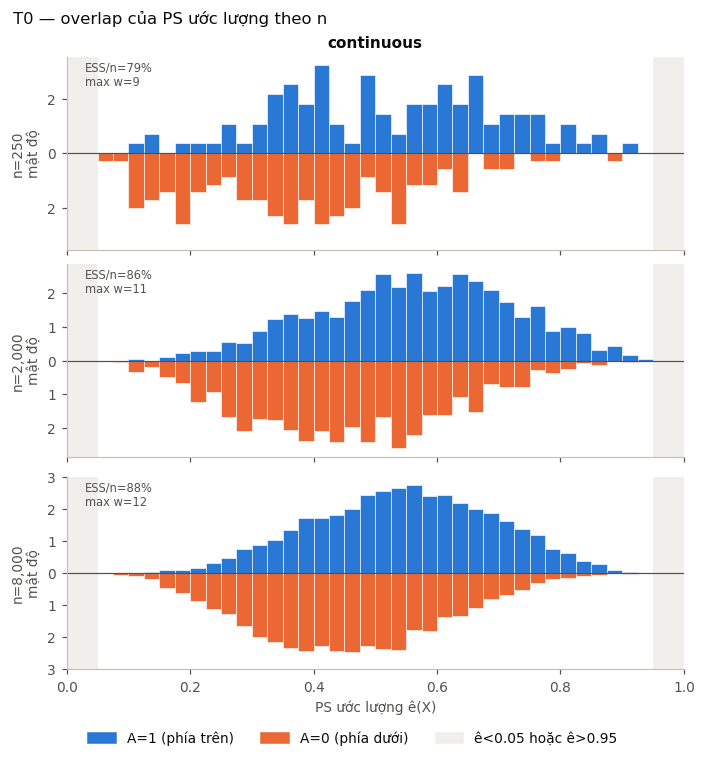

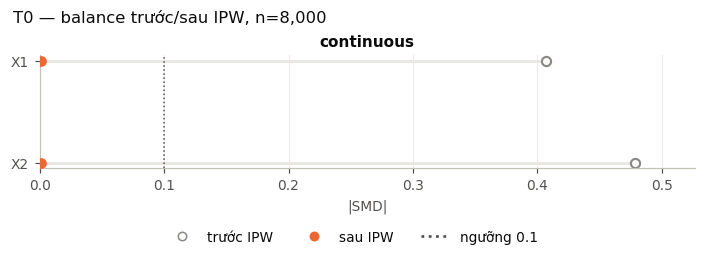

In [15]:
inspect_case("T0")

### T1 — X2 nhị phân cân bằng

**Kỳ vọng:** Nhị phân cân bằng gần baseline khi giữ Var đóng góp = 0.25.  
**Theo n:** Giống T0: RMSE giảm theo 1/√n, coverage không phụ thuộc n.

T1: gamma0=-0.0003, ATE=2.0, seed=20261021


**Ước lượng ATE và SE trên một mẫu**

method         Naive           OLS          IPTW          AIPW       
                 est     se    est     se    est     se    est     se
analysis n                                                           
binary   250   2.226  0.164  1.895  0.141  1.895  0.137  1.901  0.140
         2000  2.420  0.053  1.951  0.047  1.966  0.047  1.958  0.047
         8000  2.472  0.027  2.014  0.024  2.018  0.024  2.011  0.024

**Chẩn đoán PS và balance**

treated_rate  min_cell_count  e_min  e_max  e_outside  \
analysis n                                                             
binary   250          0.532              50  0.290  0.805        0.0   
         2000         0.496             368  0.099  0.905        0.0   
         8000         0.510            1514  0.115  0.893        0.0   

               max_weight  ess_ratio  max_abs_smd_before  max_abs_smd_after  
analysis n                                                                   
binary   250        5.132      0.933               0.386              0.010  
         2000       7.520      0.865               0.529              0.014  
         8000       8.092      0.887               0.484              0.009

**Bảng đếm A × mức X2 (binary), n=250**

X2_level,0,1
A,,
0,67,50
1,58,75


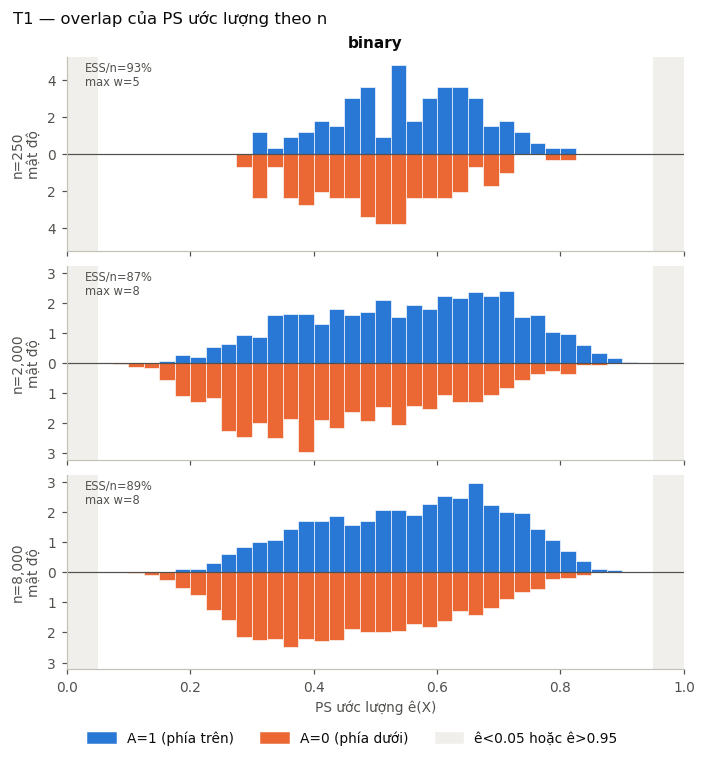

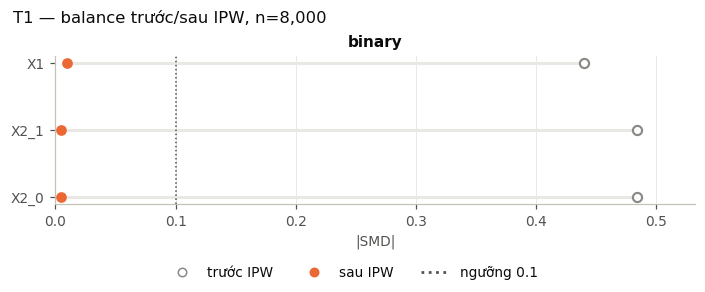

In [16]:
inspect_case("T1")

### T2 — X2 nhị phân có mức hiếm

**Kỳ vọng:** Mức hiếm làm các ô nhỏ và có thể tăng bất ổn IPTW/AIPW.  
**Theo n:** Ô nhỏ ở n nhỏ làm SE/SD và coverage của IPTW/AIPW lệch nhiều hơn; khác biệt thu hẹp khi n tăng.

T2: gamma0=0.0209, ATE=2.0, seed=20261021


**Ước lượng ATE và SE trên một mẫu**

method         Naive           OLS          IPTW          AIPW       
                 est     se    est     se    est     se    est     se
analysis n                                                           
binary   250   2.405  0.171  1.906  0.147  1.875  0.141  1.963  0.144
         2000  2.451  0.053  2.030  0.046  2.013  0.049  2.025  0.046
         8000  2.445  0.027  2.006  0.024  2.005  0.025  2.007  0.024

**Chẩn đoán PS và balance**

treated_rate  min_cell_count  e_min  e_max  e_outside  \
analysis n                                                             
binary   250          0.520               4  0.183  0.943        0.0   
         2000         0.476              32  0.123  0.947        0.0   
         8000         0.511             151  0.141  0.958        0.0   

               max_weight  ess_ratio  max_abs_smd_before  max_abs_smd_after  
analysis n                                                                   
binary   250       17.421      0.744               0.483              0.125  
         2000      13.512      0.848               0.479              0.019  
         8000      17.548      0.864               0.469              0.004

**Bảng đếm A × mức X2 (binary), n=250**

X2_level,0,1
A,,
0,116,4
1,110,20


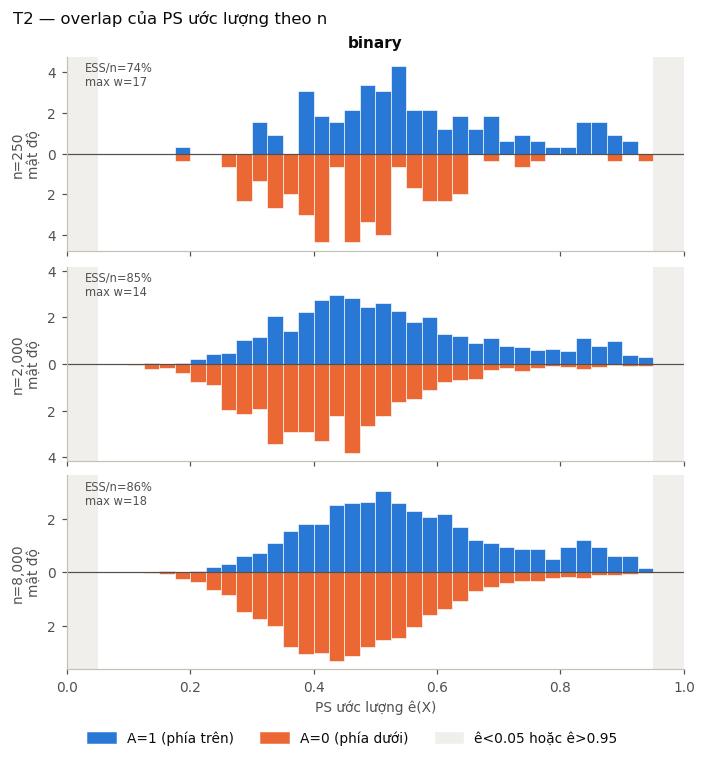

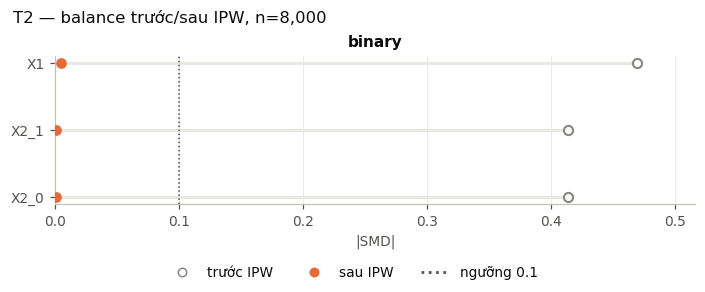

In [17]:
inspect_case("T2")

### T3a — X2 thứ bậc, hiệu ứng tuyến tính theo mức

**Kỳ vọng:** Integer và dummy cùng gần không chệch; dummy có thể mất một ít hiệu quả.  
**Theo n:** Cả hai mã hóa có RMSE giảm theo 1/√n; chênh lệch hiệu quả của dummy nhỏ.

T3a: gamma0=-0.0005, ATE=2.0, seed=20261021


**Ước lượng ATE và SE trên một mẫu**

method         Naive           OLS          IPTW          AIPW       
                 est     se    est     se    est     se    est     se
analysis n                                                           
integer  250   2.275  0.166  1.882  0.144  1.853  0.141  1.887  0.147
dummy    250   2.275  0.166  1.904  0.141  1.892  0.139  1.929  0.141
integer  2000  2.418  0.052  2.002  0.046  2.010  0.046  2.001  0.046
dummy    2000  2.418  0.052  2.000  0.046  2.007  0.046  1.999  0.046
integer  8000  2.443  0.027  1.998  0.024  1.999  0.024  1.998  0.024
dummy    8000  2.443  0.027  1.998  0.024  1.998  0.024  1.997  0.024

**Chẩn đoán PS và balance**

,,treated_rate,min_cell_count,e_min,e_max,e_outside,max_weight,ess_ratio,max_abs_smd_before,max_abs_smd_after
analysis,n,,,,,,,,,
integer,250,0.528,11,0.210,0.864,0.0,7.349,0.896,0.486,0.193
dummy,250,0.528,11,0.191,0.869,0.0,7.650,0.882,0.486,0.046
integer,2000,0.498,53,0.079,0.898,0.0,7.219,0.885,0.448,0.063
dummy,2000,0.498,53,0.092,0.903,0.0,7.481,0.883,0.448,0.016
integer,8000,0.507,236,0.085,0.919,0.0,9.736,0.886,0.466,0.019
dummy,8000,0.507,236,0.089,0.924,0.0,10.344,0.885,0.466,0.008


**Bảng đếm A × mức X2 (integer), n=250**

X2_level,0,1,2,3,4
A,,,,,
0,18,25,45,19,11
1,11,24,49,35,13


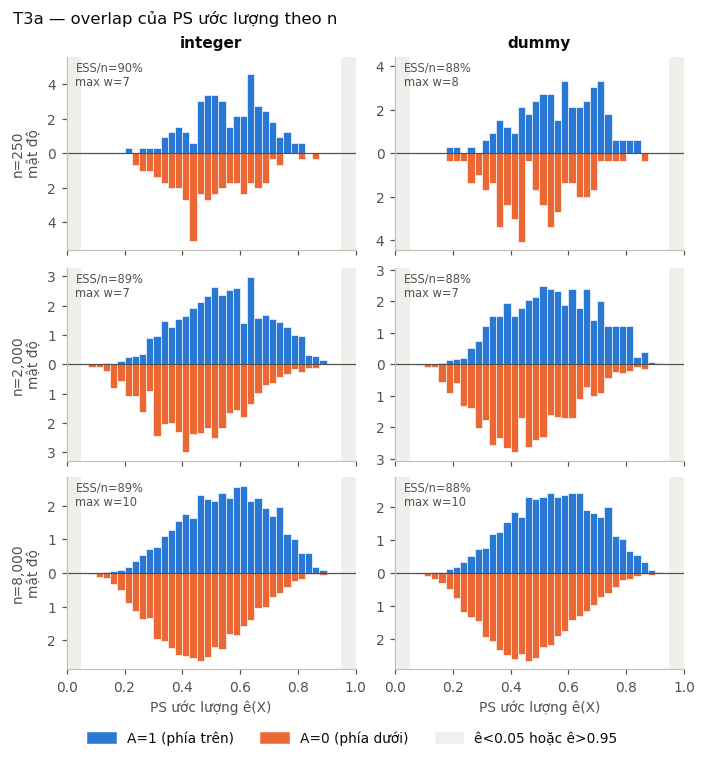

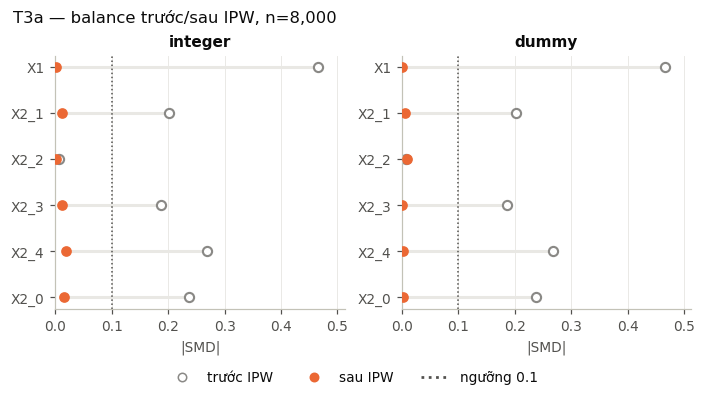

In [18]:
inspect_case("T3a")

### T3b — X2 thứ bậc, hiệu ứng phi tuyến theo mức

**Kỳ vọng:** Integer chệch; dummy gần không chệch.  
**Theo n:** Bias của integer không giảm theo n, CI hẹp lại nên coverage giảm khi n tăng; dummy giữ coverage gần 0.95.

T3b: gamma0=-0.0105, ATE=2.0, seed=20261021


**Ước lượng ATE và SE trên một mẫu**

method         Naive           OLS          IPTW          AIPW       
                 est     se    est     se    est     se    est     se
analysis n                                                           
integer  250   2.254  0.168  2.022  0.149  2.016  0.147  2.009  0.147
dummy    250   2.254  0.168  1.910  0.144  1.912  0.143  1.899  0.141
integer  2000  2.444  0.053  2.129  0.049  2.130  0.050  2.137  0.051
dummy    2000  2.444  0.053  1.981  0.047  1.973  0.048  1.982  0.047
integer  8000  2.426  0.027  2.149  0.025  2.151  0.025  2.156  0.025
dummy    8000  2.426  0.027  1.975  0.024  1.979  0.025  1.983  0.024

**Chẩn đoán PS và balance**

,,treated_rate,min_cell_count,e_min,e_max,e_outside,max_weight,ess_ratio,max_abs_smd_before,max_abs_smd_after
analysis,n,,,,,,,,,
integer,250,0.472,8,0.219,0.761,0.0,3.899,0.965,0.308,0.221
dummy,250,0.472,8,0.178,0.733,0.0,3.900,0.941,0.308,0.019
integer,2000,0.500,45,0.112,0.883,0.0,8.946,0.898,0.538,0.292
dummy,2000,0.500,45,0.061,0.896,0.0,11.665,0.851,0.538,0.014
integer,8000,0.501,197,0.125,0.871,0.0,6.285,0.930,0.449,0.332
dummy,8000,0.501,197,0.060,0.887,0.0,12.738,0.871,0.449,0.009


**Bảng đếm A × mức X2 (integer), n=250**

X2_level,0,1,2,3,4
A,,,,,
0,17,21,45,33,16
1,12,28,49,21,8


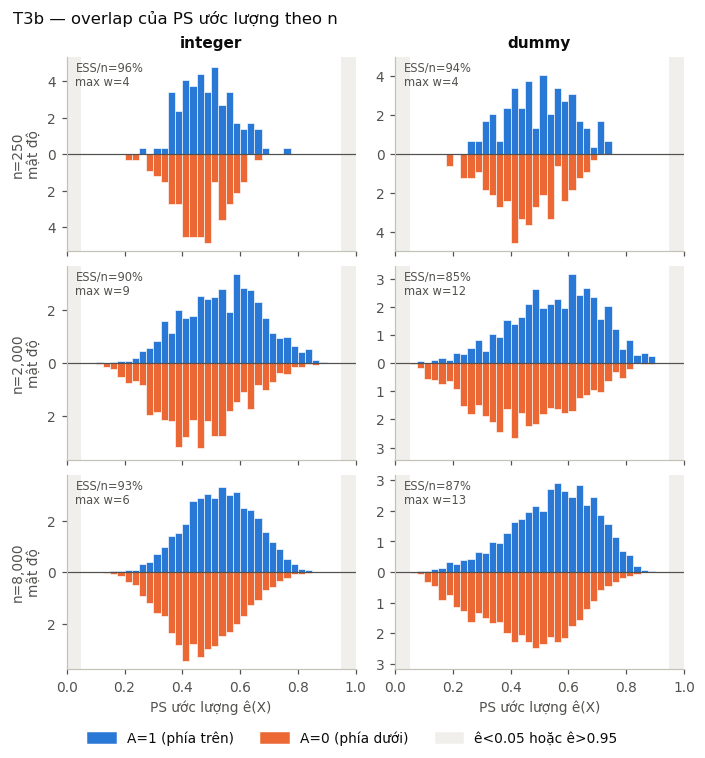

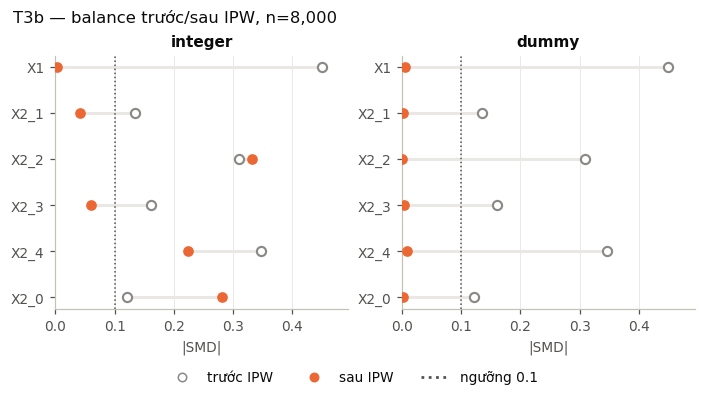

In [19]:
inspect_case("T3b")

### T4 — X2 danh nghĩa

**Kỳ vọng:** Label encoding sai dạng so với dummy; dấu và độ lớn bias phụ thuộc g/h.  
**Theo n:** Như T3b: bias của label giữ nguyên theo n nên coverage giảm khi n tăng.

T4: gamma0=-0.0034, ATE=2.0, seed=20261021


**Ước lượng ATE và SE trên một mẫu**

method         Naive           OLS          IPTW          AIPW       
                 est     se    est     se    est     se    est     se
analysis n                                                           
dummy    250   2.244  0.174  1.857  0.138  1.878  0.136  1.853  0.136
label    250   2.244  0.174  2.016  0.155  2.003  0.153  2.004  0.151
dummy    2000  2.472  0.052  2.056  0.047  2.051  0.049  2.058  0.047
label    2000  2.472  0.052  2.254  0.049  2.255  0.049  2.250  0.049
dummy    8000  2.370  0.027  1.975  0.024  1.979  0.024  1.976  0.024
label    8000  2.370  0.027  2.174  0.025  2.175  0.025  2.175  0.025

**Chẩn đoán PS và balance**

,,treated_rate,min_cell_count,e_min,e_max,e_outside,max_weight,ess_ratio,max_abs_smd_before,max_abs_smd_after
analysis,n,,,,,,,,,
dummy,250,0.484,10,0.091,0.843,0.0,4.735,0.899,0.418,0.027
label,250,0.484,10,0.150,0.821,0.0,5.033,0.931,0.418,0.365
dummy,2000,0.486,74,0.063,0.904,0.0,15.856,0.845,0.496,0.013
label,2000,0.486,74,0.147,0.829,0.0,6.802,0.935,0.496,0.419
dummy,8000,0.505,350,0.082,0.902,0.0,10.514,0.881,0.430,0.005
label,8000,0.505,350,0.175,0.819,0.0,5.699,0.950,0.430,0.399


**Bảng đếm A × mức X2 (dummy), n=250**

X2_level,0,1,2,3
A,,,,
0,49,28,38,14
1,51,44,16,10


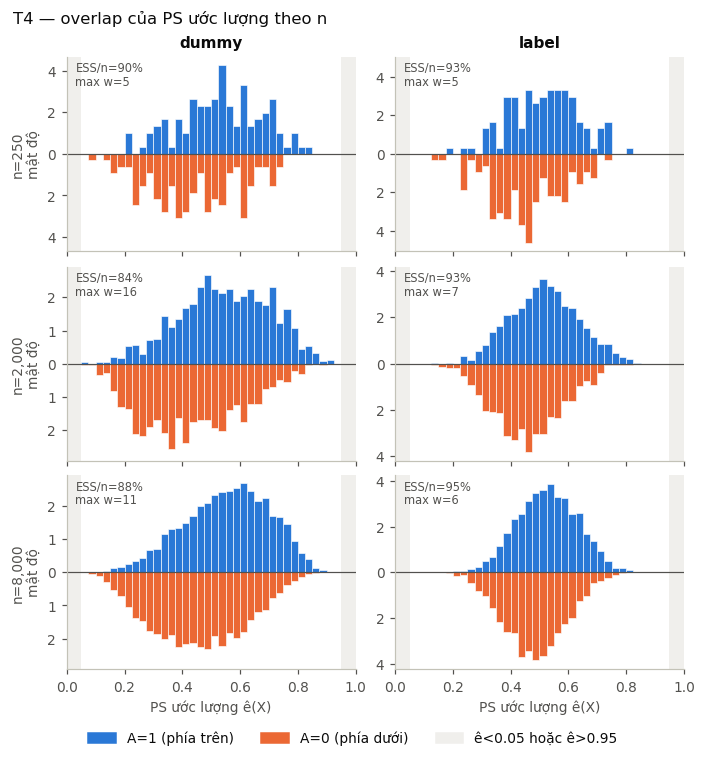

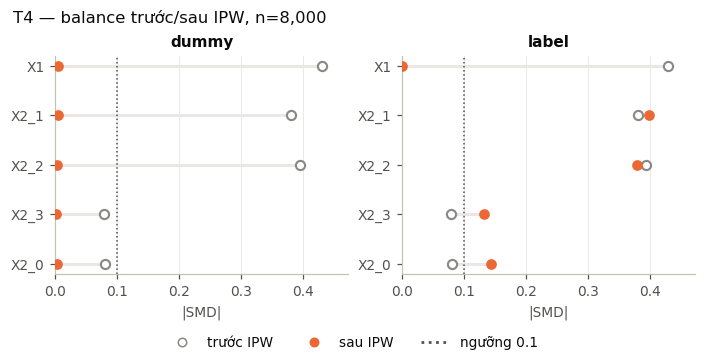

In [20]:
inspect_case("T4")

### T5 — Mức hiếm có overlap kém

**Kỳ vọng:** Trọng số cực đoan, ESS thấp, có thể có ô control rỗng ở mức hiếm.  
**Theo n:** n nhỏ: mức hiếm có rất ít control nên nhiều rep có ô rỗng hoặc fit thất bại; tăng n giảm tỉ lệ lỗi nhưng ESS/n vẫn thấp vì overlap kém là đặc tính của DGP.

T5: gamma0=-0.2262, ATE=2.0, seed=20261021


**Ước lượng ATE và SE trên một mẫu**

method         Naive           OLS          IPTW          AIPW       
                 est     se    est     se    est     se    est     se
analysis n                                                           
dummy    250   2.334  0.166  1.849  0.149  1.965  0.143  1.933  0.137
         2000  2.456  0.053  2.030  0.048  1.926  0.116  2.033  0.046
         8000  2.461  0.027  2.027  0.024  2.064  0.038  2.076  0.031

**Chẩn đoán PS và balance**

treated_rate  min_cell_count  e_min  e_max  e_outside  \
analysis n                                                             
dummy    250          0.512               1  0.149  0.987      0.000   
         2000         0.478               3  0.117  0.996      0.020   
         8000         0.509              22  0.128  0.995      0.004   

               max_weight  ess_ratio  max_abs_smd_before  max_abs_smd_after  
analysis n                                                                   
dummy    250       16.982      0.754               0.615              0.095  
         2000     171.612      0.190               0.643              0.155  
         8000     133.524      0.411               0.657              0.021

**Bảng đếm A × mức X2 (dummy), n=250**

X2_level,0,1,2
A,,,
0,57,64,1
1,56,49,23


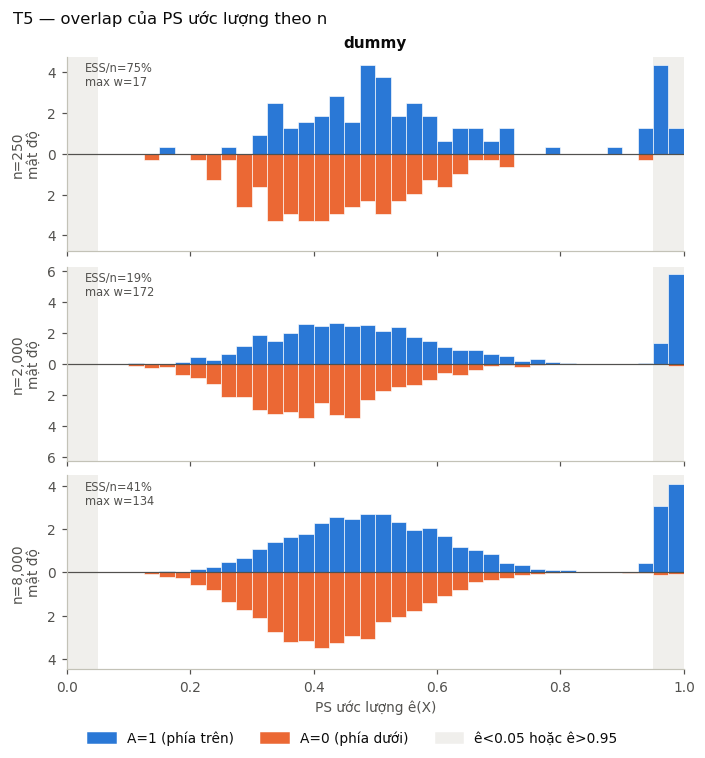

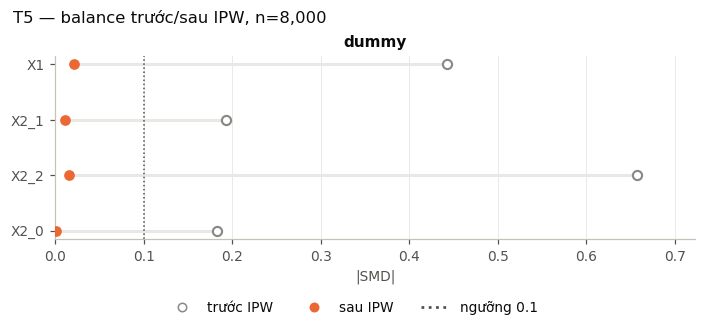

In [21]:
inspect_case("T5")

### T6 — Rời rạc hóa X2 liên tục

**Kỳ vọng:** Bias còn sót giảm khi tăng số nhóm; tăng n không xóa bias do rời rạc hóa.  
**Theo n:** Bias của các cách chia nhóm gần như không đổi theo n, nên coverage giảm dần khi n tăng, rõ nhất khi ít nhóm.

T6: gamma0=-0.0012, ATE=2.0, seed=20261021


**Ước lượng ATE và SE trên một mẫu**

method           Naive           OLS          IPTW          AIPW       
                   est     se    est     se    est     se    est     se
analysis   n                                                           
continuous 250   2.338  0.164  1.842  0.146  1.866  0.143  1.858  0.143
omit_X2    250   2.338  0.164  2.051  0.146  2.067  0.144  2.059  0.144
binned_2   250   2.338  0.164  1.958  0.148  1.966  0.146  1.953  0.147
binned_3   250   2.338  0.164  1.890  0.147  1.923  0.144  1.890  0.145
binned_5   250   2.338  0.164  1.875  0.149  1.897  0.148  1.865  0.149
binned_10  250   2.338  0.164  1.868  0.152  1.902  0.147  1.892  0.145
continuous 2000  2.418  0.052  1.973  0.046  1.975  0.050  1.972  0.047
omit_X2    2000  2.418  0.052  2.181  0.049  2.178  0.050  2.181  0.050
binned_2   2000  2.418  0.052  2.042  0.048  2.044  0.051  2.044  0.049
binned_3   2000  2.418  0.052  2.008  0.047  2.006  0.051  2.013  0.048
binned_5   2000  2.418  0.052  1.986  0.046  1.985  0.050  1.987  0.047
binned_10  2000  2.418  0.052  1.980  0.047  1.979  0.051  1.979  0.047
continuous 8000  2.454  0.027  2.020  0.024  2.015  0.025  2.016  0.024
omit_X2    8000  2.454  0.027  2.261  0.026  2.261  0.026  2.261  0.026
binned_2   8000  2.454  0.027  2.111  0.024  2.111  0.025  2.109  0.025
binned_3   8000  2.454  0.027  2.072  0.024  2.074  0.024  2.072  0.024
binned_5   8000  2.454  0.027  2.051  0.024  2.048  0.024  2.049  0.024
binned_10  8000  2.454  0.027  2.028  0.024  2.026  0.025  2.025  0.024

**Chẩn đoán PS và balance**

,,treated_rate,min_cell_count,e_min,e_max,e_outside,max_weight,ess_ratio,max_abs_smd_before,max_abs_smd_after
analysis,n,,,,,,,,,
continuous,250,0.444,NaN,0.070,0.903,0.0,9.051,0.785,0.695,0.014
omit_X2,250,0.444,NaN,0.170,0.738,0.0,4.031,0.938,0.435,0.007
binned_2,250,0.444,38.0,0.106,0.822,0.0,5.738,0.860,0.560,0.015
binned_3,250,0.444,21.0,0.079,0.868,0.0,7.474,0.827,0.589,0.034
binned_5,250,0.444,11.0,0.059,0.876,0.0,9.794,0.783,0.540,0.023
binned_10,250,0.444,5.0,0.065,0.869,0.0,10.238,0.781,0.435,0.031
continuous,2000,0.510,NaN,0.076,0.937,0.0,11.076,0.862,0.519,0.008
omit_X2,2000,0.510,NaN,0.151,0.858,0.0,7.057,0.925,0.519,0.006
binned_2,2000,0.510,393.0,0.098,0.908,0.0,10.868,0.875,0.519,0.004


... (4 outputs left out)

**Bảng đếm A × mức X2 (binned_5), n=250**

X2_level,0,1,2,3,4
A,,,,,
0,43,23,36,22,15
1,11,15,21,32,32


**Bảng đếm A × mức X2 (binned_10), n=250**

X2_level,0,1,2,3,4,5,6,7,8,9
A,,,,,,,,,,
0,27,16,13,10,19,17,14,8,9,6
1,6,5,9,6,12,9,17,15,19,13


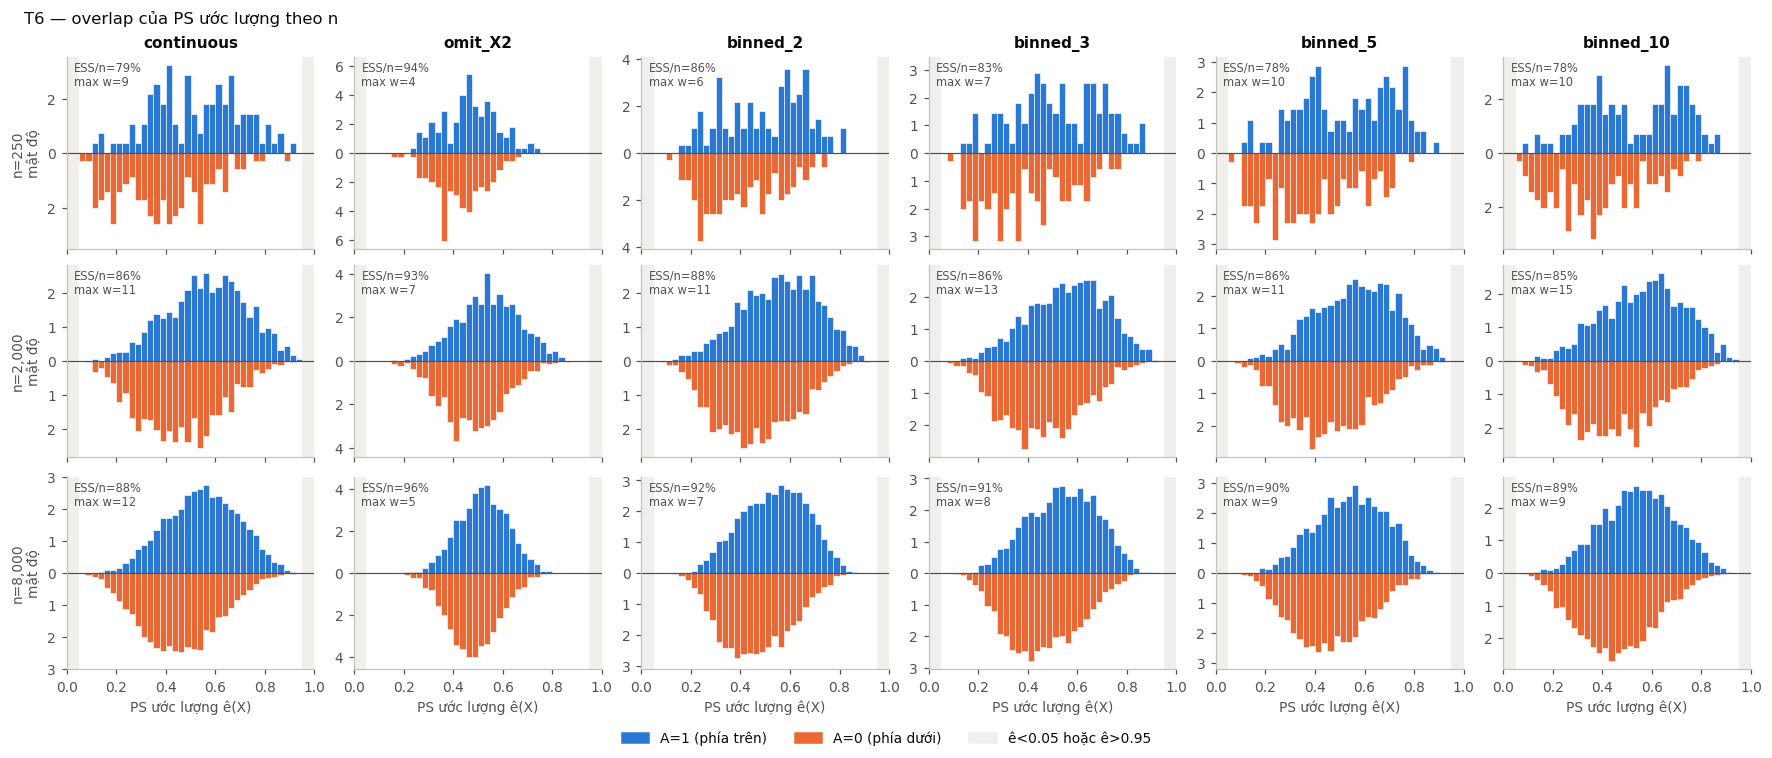

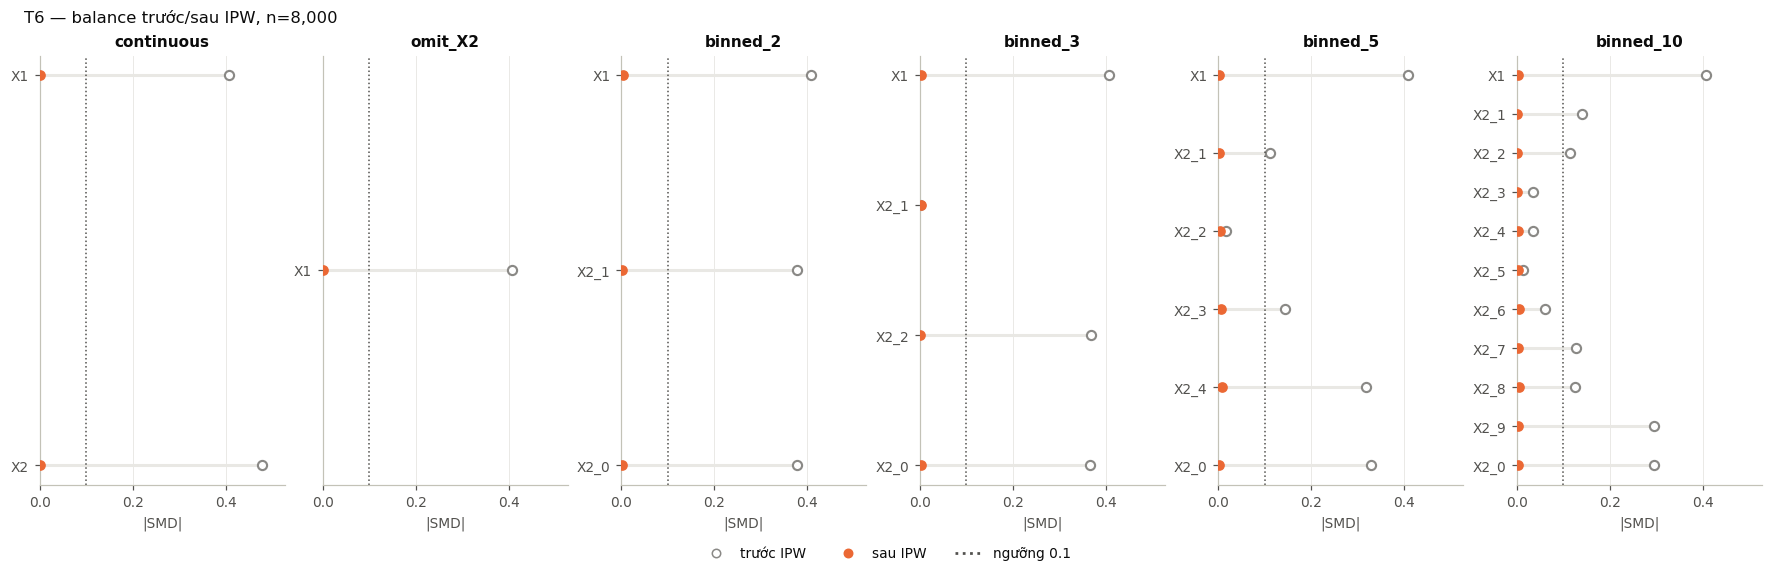

In [22]:
inspect_case("T6")

## 10. Monte Carlo trên lưới n
`SeedSequence([seed, mã_kịch_bản, n]).spawn(R)` tạo seed con và truyền vào `simulate`. Các analysis của cùng rep dùng cùng dữ liệu (so sánh ghép cặp).
CSV raw có khóa scenario/analysis/n/rep/method; diagnostics lưu riêng một dòng/analysis/rep, gồm bảng đếm ô định tính dạng JSON.

In [23]:
def scenario_code(scenario):
    """Mã seed ổn định theo tên kịch bản; không phụ thuộc thứ tự chạy/lọc."""
    return sum((i+1)*ord(c) for i, c in enumerate(scenario))


def run_one_rep(scenario, n, rep, child_seed):
    """Một mẫu, mọi cách phân tích: trả về dòng ước lượng và dòng chẩn đoán."""
    df, _ = simulate(n, scenario, child_seed)
    rows, diags = [], []
    for analysis, spec in ANALYSES[scenario].items():
        estimates, e, status, ps_status = estimate_all(df, make_design(df, spec))
        key = dict(scenario=scenario, analysis=analysis, n=n, rep=rep)
        for method, (est, se) in estimates.items():
            rows.append({**key, "method": method, "est": est, "se": se,
                         "truth": TAU, "status": status[method]})
        diags.append({**key, "ps_status": ps_status, **diagnostics(df, spec, e)})
    return rows, diags


def run_mc(R=R, seed=SEED, scenarios=None, n_values=N_VALUES):
    if R < 2:
        raise ValueError("R phải >= 2.")
    selected = list(SCENARIOS) if scenarios is None else list(scenarios)
    all_rows, all_diagnostics = [], []
    for scenario in selected:
        rows, diags = [], []
        start = time.perf_counter()
        for n in n_grid(scenario, n_values):
            children = np.random.SeedSequence([seed, scenario_code(scenario), n]).spawn(R)
            for rep, child in enumerate(children):
                r, d = run_one_rep(scenario, n, rep, child)
                rows += r
                diags += d
        # Lưu raw trước khi tóm tắt; một dòng/method/rep dù fit thất bại.
        rows, diags = pd.DataFrame(rows), pd.DataFrame(diags)
        rows.to_csv(RESULT_DIR / f"{scenario}.csv", index=False)
        diags.to_csv(RESULT_DIR / f"{scenario}_diagnostics.csv", index=False)
        all_rows.append(rows)
        all_diagnostics.append(diags)
        print(f"{scenario:>4}: n={list(n_grid(scenario, n_values))}, R={R} "
              f"— {time.perf_counter()-start:.0f}s", flush=True)
    return pd.concat(all_rows, ignore_index=True), pd.concat(all_diagnostics, ignore_index=True)

In [24]:
def summarize_mc(raw):
    rows = []
    for key, group in raw.groupby(["scenario", "analysis", "n", "method"], sort=False):
        ok = group.status.eq("ok") & np.isfinite(group.est) & np.isfinite(group.se)
        valid = group.loc[ok]
        est, se = valid.est.to_numpy(), valid.se.to_numpy()
        truth = valid.truth.to_numpy()
        sd = est.std(ddof=1) if len(est) > 1 else np.nan
        coverage = np.mean(np.abs(est-truth) <= Z95*se) if len(est) else np.nan
        rows.append({**dict(zip(("scenario", "analysis", "n", "method"), key)),
                     "R": len(group), "valid_reps": len(valid), "failed_reps": int((~ok).sum()),
                     "failure_rate": (~ok).mean(),
                     "bias": np.mean(est-truth) if len(est) else np.nan,
                     "mc_se_bias": sd/np.sqrt(len(est)) if len(est) else np.nan,
                     "emp_sd": sd, "mean_se": se.mean() if len(est) else np.nan,
                     "se_sd_ratio": se.mean()/sd if sd > 0 else np.nan,
                     "rmse": np.sqrt(np.mean((est-truth)**2)) if len(est) else np.nan,
                     "coverage": coverage,
                     "mc_se_coverage": np.sqrt(coverage*(1-coverage)/len(est)) if len(est) else np.nan,
                     "mean_ci_width": 2*Z95*se.mean() if len(est) else np.nan})
    return pd.DataFrame(rows)


def summarize_diagnostics(diags):
    grouped = diags.groupby(["scenario", "analysis", "n"], sort=False)
    means = grouped[["treated_rate", "e_min", "e_max", "e_outside", "max_weight", "ess_ratio",
                     "ess_treated_ratio", "ess_control_ratio", "max_abs_smd_before",
                     "max_abs_smd_after", "x3_smd_after", "x2_continuous_smd_after"]].mean()
    means["R"] = grouped.size()
    means["ps_valid_reps"] = grouped.ps_status.apply(lambda s: s.eq("ok").sum())
    means["ps_failed_reps"] = grouped.ps_status.apply(lambda s: s.ne("ok").sum())
    means["empty_cell_reps"] = grouped.has_empty_cell.sum()
    means["empty_cell_rate"] = grouped.has_empty_cell.mean()
    means["min_cell_count_observed"] = grouped.min_cell_count.min()
    return means.reset_index()


def save_metadata(part):
    metadata = {"part": part, "R": R, "R_full": R_FULL, "seed": SEED, "n": list(N_VALUES),
                "extra_n": {s: list(v) for s, v in EXTRA_N.items()},
                "n_by_scenario": {s: list(n_grid(s)) for s in SCENARIOS}, "tau": TAU,
                "beta": BETA, "gamma": GAMMA, "sigma": SIGMA, "n_ref": N_REF,
                "calibration_seed": 12345, "bin_cutpoints": "population N(0,1) quantiles",
                "ps": "unpenalized estimated logistic, no clipping",
                "versions": {"numpy": np.__version__, "pandas": pd.__version__,
                             "scipy": scipy.__version__, "statsmodels": statsmodels.__version__},
                "gamma0": {s: _calibrate_gamma0(s)[0] for s in SCENARIOS},
                "rare_gamma": {s: _calibrate_gamma0(s)[1] for s in SCENARIOS}}
    (RESULT_DIR / f"part_{part}_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

In [25]:
if RUN_MC:
    raw, diagnostic_raw = run_mc()
    save_metadata("A")
    print(f"Đã lưu {len(raw):,} dòng ước lượng; {len(diagnostic_raw):,} dòng diagnostics.")
else:
    print("RUN_MC=False: bỏ qua mô phỏng, đọc CSV đã lưu ở mục 11.")

  T0: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 46s
  T1: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 74s
  T2: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 79s
 T3a: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 187s
 T3b: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 180s
  T4: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 151s
  T5: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 89s


/home/doan/anaconda3/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:2383: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))


  T6: n=[250, 500, 1000, 2000, 4000, 8000], R=1000 — 483s
Đã lưu 384,000 dòng ước lượng; 96,000 dòng diagnostics.


## 11. Tóm tắt từ CSV
Đọc lại raw đã lưu để có thể tính lại metrics mà không chạy mô phỏng. `valid_reps`, `failed_reps`, `failure_rate` nêu mẫu số; bias, SD, SE, RMSE và coverage tính trên các lần thành công. Khi có failure, coverage này là coverage có điều kiện và cần đọc cùng failure rate. `mc_se_bias=SD/sqrt(valid_reps)`; thêm MC SE của coverage để diễn giải dao động Monte Carlo.

In [26]:
raw = pd.concat([pd.read_csv(RESULT_DIR / f"{s}.csv") for s in SCENARIOS], ignore_index=True)
diagnostic_raw = pd.concat([pd.read_csv(RESULT_DIR / f"{s}_diagnostics.csv") for s in SCENARIOS],
                           ignore_index=True)
summary = summarize_mc(raw)
diagnostic_summary = summarize_diagnostics(diagnostic_raw)
summary.to_csv(RESULT_DIR / "part_A_summary.csv", index=False)
diagnostic_summary.to_csv(RESULT_DIR / "part_A_diagnostic_summary.csv", index=False)

# Kiểm tra đầy đủ khóa, lưới n và số dòng sau khi đọc lại CSV.
for s in SCENARIOS:
    found = tuple(sorted(raw.loc[raw.scenario.eq(s), "n"].unique()))
    assert found == n_grid(s), f"{s}: CSV có n={found}, cần {n_grid(s)} — hãy chạy lại MC."
assert not raw.duplicated(["scenario", "analysis", "n", "rep", "method"]).any()
assert not diagnostic_raw.duplicated(["scenario", "analysis", "n", "rep"]).any()
assert raw.groupby(["scenario", "analysis", "n", "rep"]).size().eq(len(METHODS)).all()
assert summary.R.eq(R).all()
assert (summary.valid_reps + summary.failed_reps).eq(R).all()
assert summary.valid_reps.eq(raw[raw.status.eq("ok")].groupby(
    ["scenario", "analysis", "n", "method"], sort=False).size().to_numpy()).all()
print(f"Kiểm tra CSV: {len(summary)} dòng tóm tắt; khóa duy nhất, đủ lưới n, method/rep và failure count: PASS")

# Bảng tổng hợp MỘT file, bố cục như file Excel tổng hợp: Scenario | Analysis | Method,
# rồi Bias theo n, rồi Coverage theo n (hai hàng tiêu đề).
def write_bias_coverage_csv(summary, path):
    ns = sorted(summary.n.unique())
    wide = summary.pivot_table(index=["scenario", "analysis", "method"], columns="n",
                               values=["bias", "coverage"], sort=False)
    order = [(s, a, m) for s in SCENARIOS for a in ANALYSES[s] for m in METHODS]
    wide = wide.reindex(pd.MultiIndex.from_tuples(order))
    with open(path, "w", newline="", encoding="utf-8") as f:
        out = csv.writer(f)
        out.writerow(["Scenario", "Analysis", "Method", "Bias"] + [""]*(len(ns)-1)
                     + ["Coverage"] + [""]*(len(ns)-1))
        out.writerow(["", "", ""] + ns + ns)
        for key, row in wide.iterrows():
            values = [row[("bias", n)] for n in ns] + [row[("coverage", n)] for n in ns]
            out.writerow(list(key) + ["" if pd.isna(v) else round(float(v), 6) for v in values])
    return len(wide)


rows_written = write_bias_coverage_csv(summary, RESULT_DIR / "part_A_bias_coverage_all_T.csv")
print(f"Đã ghi {rows_written} dòng vào part_A_bias_coverage_all_T.csv")


Kiểm tra CSV: 384 dòng tóm tắt; khóa duy nhất, đủ lưới n, method/rep và failure count: PASS
Đã ghi 64 dòng vào part_A_bias_coverage_all_T.csv


In [27]:
# Mốc baseline ở mọi n: Naive dự kiến chệch nên chỉ kiểm tra estimator điều chỉnh.
base = summary[(summary.scenario == next(iter(SCENARIOS))) & (summary.method != "Naive")].copy()
base["bias_within_3_mc_se"] = base.bias.abs() <= 3*base.mc_se_bias
base["coverage_near_95"] = (base.coverage-.95).abs() <= 3*np.sqrt(.95*.05/base.valid_reps)
base["se_sd_near_1"] = base.se_sd_ratio.between(.8, 1.2)
display(base[["n", "method", "bias", "mc_se_bias", "coverage", "se_sd_ratio",
              "bias_within_3_mc_se", "coverage_near_95", "se_sd_near_1"]].round(4))
assert base.failed_reps.eq(0).all()
assert base.bias_within_3_mc_se.all() and base.se_sd_near_1.all()
# Coverage: CI Wald có sai số hữu hạn mẫu (SE hơi thấp hơn SD thật khi n nhỏ, nhất là AIPW),
# nên ở n < 500 chỉ cảnh báo; từ n >= 500 vẫn yêu cầu nằm trong 3 MC SE quanh 0.95.
small_n = base.n < 500
assert base.loc[~small_n, "coverage_near_95"].all()
off = base.loc[small_n & ~base.coverage_near_95, ["n", "method", "coverage", "se_sd_ratio"]]
if len(off):
    print("Cảnh báo (không dừng): coverage ở n nhỏ lệch quá 3 MC SE quanh 0.95:")
    print(off.round(3).to_string(index=False))
print("Baseline Monte Carlo ở mọi n: PASS (bias, SE/SD ở mọi n; coverage từ n >= 500).")


,n,method,bias,mc_se_bias,coverage,se_sd_ratio,bias_within_3_mc_se,coverage_near_95,se_sd_near_1
1,250,OLS,0.0047,0.0044,0.935,0.9545,True,True,True
2,250,IPTW,0.0065,0.0046,0.935,0.9443,True,True,True
3,250,AIPW,0.0059,0.0045,0.927,0.9460,True,False,True
5,500,OLS,0.0002,0.0030,0.948,0.9960,True,True,True
6,500,IPTW,0.0007,0.0032,0.938,0.9765,True,True,True
7,500,AIPW,0.0001,0.0031,0.943,0.9899,True,True,True
9,1000,OLS,-0.0001,0.0020,0.958,1.0459,True,True,True
10,1000,IPTW,0.0011,0.0021,0.958,1.0362,True,True,True
11,1000,AIPW,0.0001,0.0021,0.957,1.0435,True,True,True
13,2000,OLS,-0.0001,0.0015,0.940,0.9765,True,True,True


Cảnh báo (không dừng): coverage ở n nhỏ lệch quá 3 MC SE quanh 0.95:
  n method  coverage  se_sd_ratio
250   AIPW     0.927        0.946
Baseline Monte Carlo ở mọi n: PASS (bias, SE/SD ở mọi n; coverage từ n >= 500).


## 12. Tổng quan theo n
Hai bản đồ nhiệt gom mọi kịch bản × cách phân tích × n cho ba estimator điều chỉnh
(Naive luôn chệch khoảng +0.45 nên để ở bảng chi tiết mục 13).
Ô trống là n không chạy cho kịch bản đó (mặc định mọi kịch bản đều chạy đủ lưới n).
Đọc theo hàng: bias không đổi màu khi n tăng nhưng coverage đỏ dần là dấu hiệu bias do sai dạng mô hình, không phải nhiễu mẫu nhỏ.

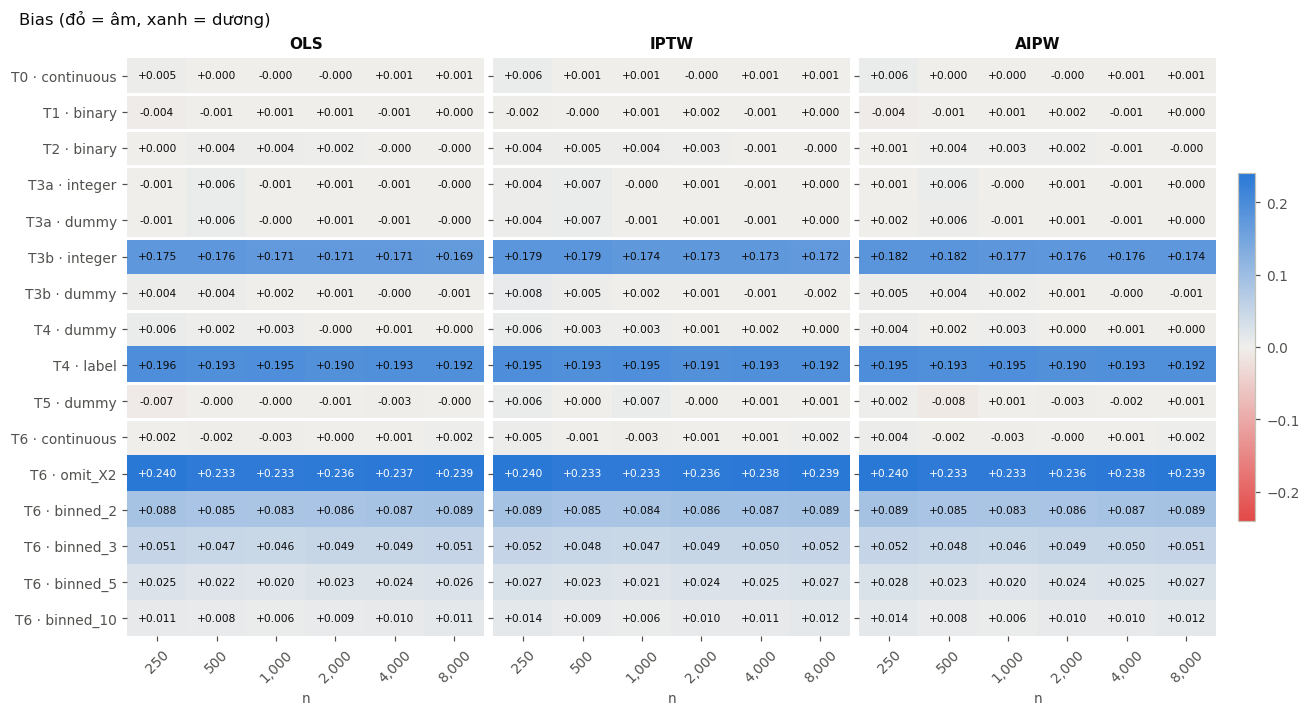

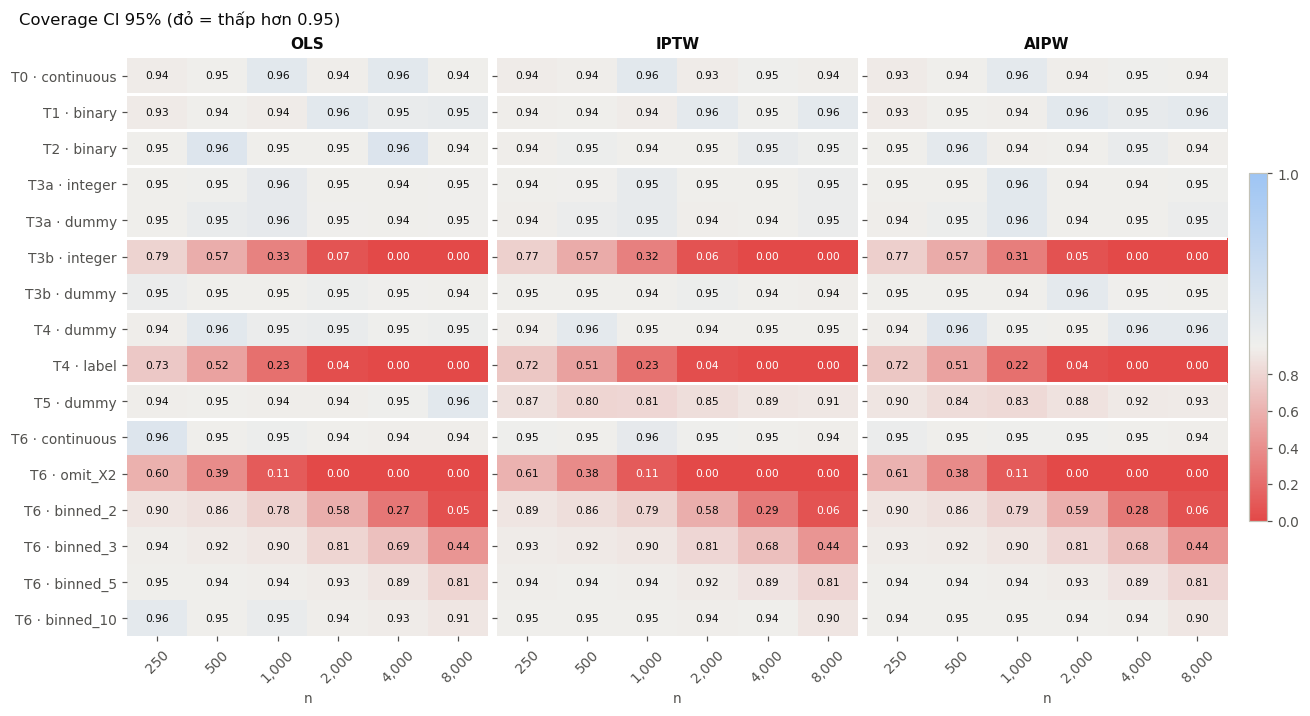

In [28]:
save_fig(plot_overview_heatmap(summary, "bias"), "overview_bias")
save_fig(plot_overview_heatmap(summary, "coverage"), "overview_coverage")

## 13. Kỳ vọng → Kết quả → Giải thích
Các bảng và hình dưới được sinh từ kết quả thực tế của lần chạy, không suy diễn từ pilot.
Mỗi kịch bản gồm: bảng bias/coverage theo n (đủ cả Naive), hình chất lượng ước lượng theo n,
hình phân phối ước lượng qua các rep, và hình chẩn đoán overlap. So sánh độ chệch với MC SE;
chênh lệch nhỏ ở R=200 cần xác nhận bằng R=1000.

In [29]:
def report_scenario(scenario):
    show_expectation(scenario)
    s = summary[summary.scenario.eq(scenario)]
    d = diagnostic_summary[diagnostic_summary.scenario.eq(scenario)]
    order = pd.MultiIndex.from_product([list(ANALYSES[scenario]), METHODS])
    table = (s.pivot_table(index=["analysis", "method"], columns="n",
                           values=["bias", "coverage", "se_sd_ratio", "failure_rate"])
             .reindex(order))
    display(Markdown("**Kết quả Monte Carlo** (cột = n)"))
    display(table[["bias", "coverage"]].round(3))
    if table["failure_rate"].fillna(0).gt(0).any().any():
        display(Markdown("**Tỉ lệ rep thất bại** (chỉ số trên tính trên rep thành công)"))
        display(table["failure_rate"].round(3))
    save_fig(plot_metrics_vs_n(s, scenario), f"{scenario}_metrics_by_n")
    save_fig(plot_estimate_distribution(raw[raw.scenario.eq(scenario)], scenario),
             f"{scenario}_estimates_by_n")
    save_fig(plot_diagnostics_vs_n(d, scenario), f"{scenario}_diagnostics_by_n")
    display(Markdown(f"**Giải thích:** {EXPECTATIONS[scenario]['explain']}"))

### T0 — X2 liên tục (baseline)

**Kỳ vọng:** Các estimator điều chỉnh gần không chệch, SE/SD gần 1, coverage gần 0.95; Naive chệch.  
**Theo n:** Bias ≈ 0 ở mọi n; RMSE giảm theo 1/√n; coverage ổn định quanh 0.95.

**Kết quả Monte Carlo** (cột = n)

bias                                    coverage         \
n                  250    500    1000   2000   4000   8000     250    500    
continuous Naive  0.459  0.452  0.448  0.448  0.450  0.450    0.167  0.012   
           OLS    0.005  0.000 -0.000 -0.000  0.001  0.001    0.935  0.948   
           IPTW   0.006  0.001  0.001 -0.000  0.001  0.001    0.935  0.938   
           AIPW   0.006  0.000  0.000 -0.000  0.001  0.001    0.927  0.943   

                                              
n                  1000   2000   4000   8000  
continuous Naive  0.000  0.000  0.000  0.000  
           OLS    0.958  0.940  0.958  0.945  
           IPTW   0.958  0.934  0.951  0.938  
           AIPW   0.957  0.936  0.951  0.944

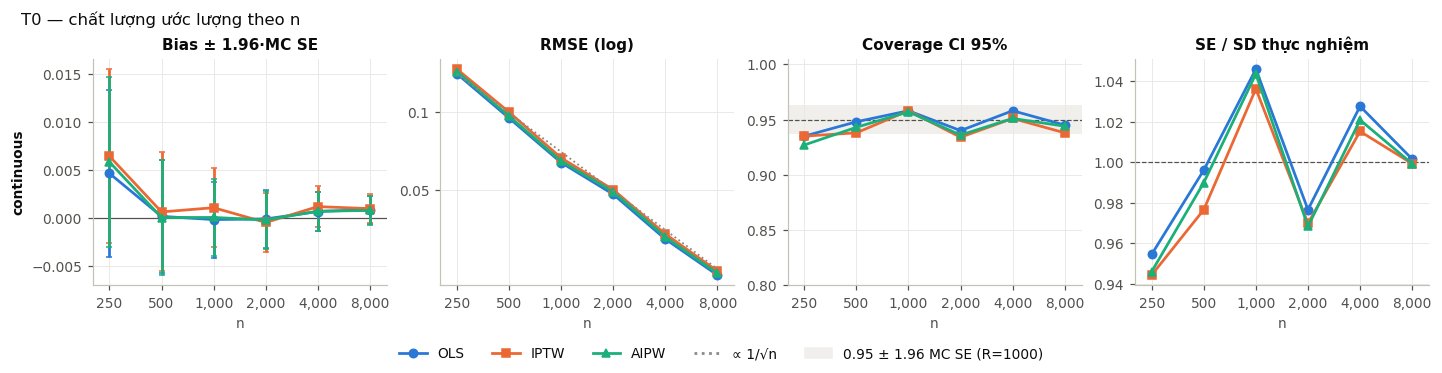

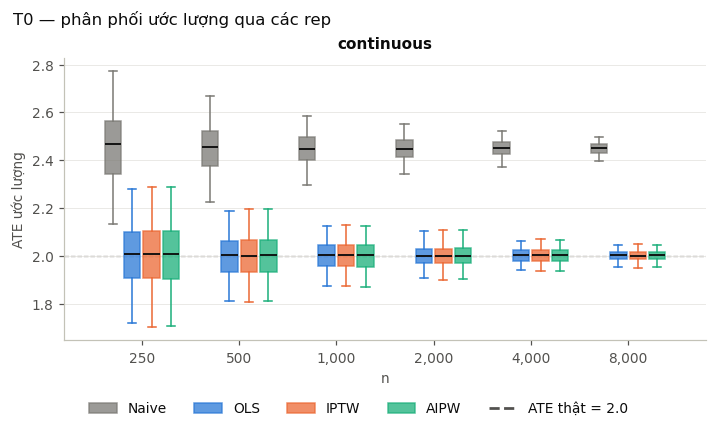

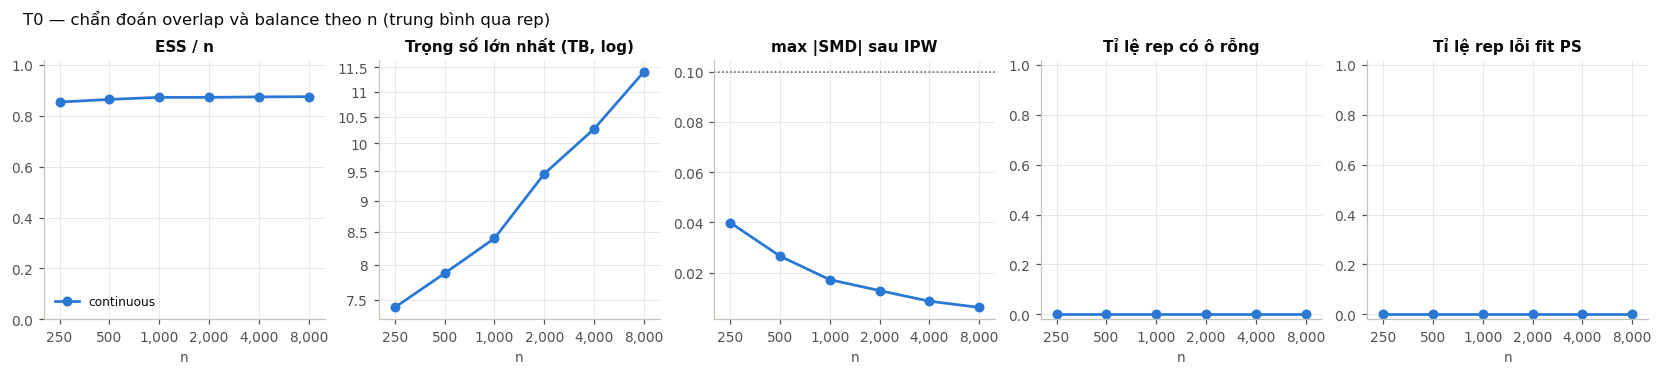

**Giải thích:** DGP và mô hình điều chỉnh đều tuyến tính đúng dạng.

In [30]:
report_scenario("T0")

### T1 — X2 nhị phân cân bằng

**Kỳ vọng:** Nhị phân cân bằng gần baseline khi giữ Var đóng góp = 0.25.  
**Theo n:** Giống T0: RMSE giảm theo 1/√n, coverage không phụ thuộc n.

**Kết quả Monte Carlo** (cột = n)

bias                                    coverage                \
n              250    500    1000   2000   4000   8000     250    500    1000   
binary Naive  0.448  0.458  0.457  0.456  0.455  0.457    0.165  0.011  0.000   
       OLS   -0.004 -0.001  0.001  0.001 -0.001  0.000    0.926  0.943  0.935   
       IPTW  -0.002 -0.000  0.001  0.002 -0.001  0.000    0.936  0.945  0.935   
       AIPW  -0.004 -0.001  0.001  0.002 -0.001  0.000    0.927  0.949  0.937   

                                   
n              2000   4000   8000  
binary Naive  0.000  0.000  0.000  
       OLS    0.958  0.954  0.955  
       IPTW   0.957  0.951  0.957  
       AIPW   0.958  0.955  0.957

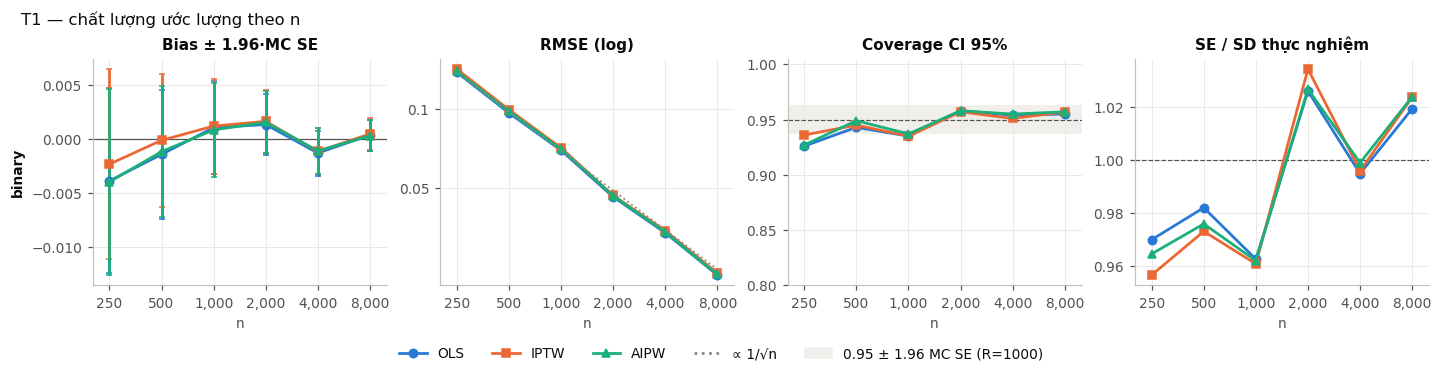

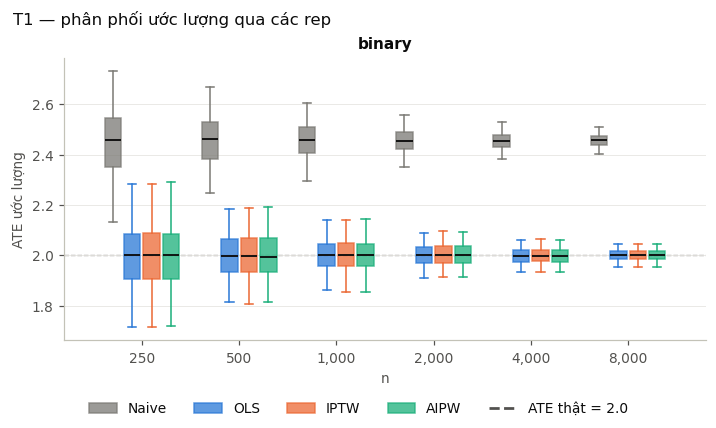

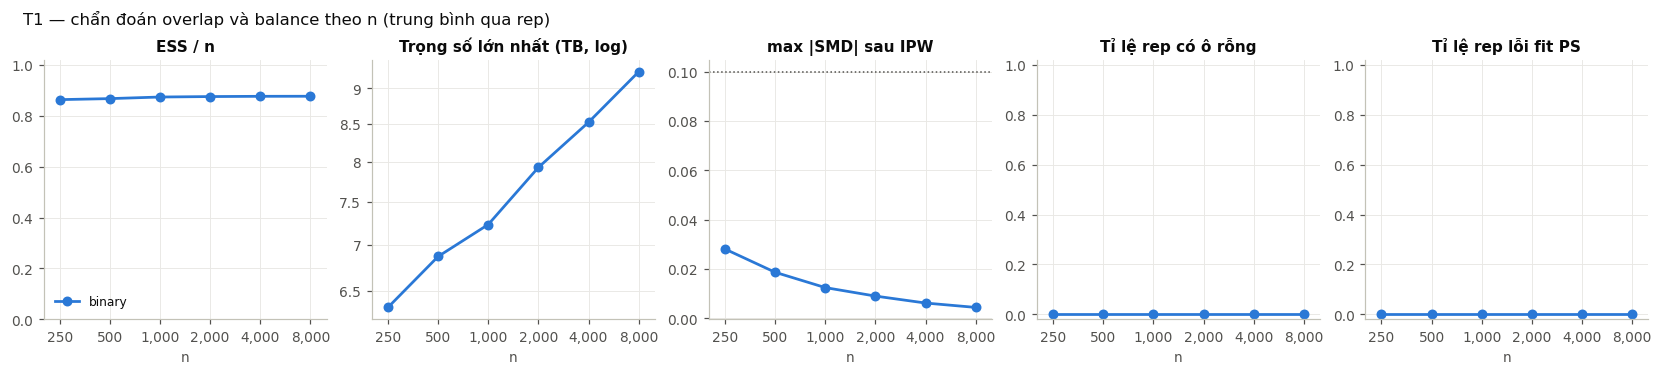

**Giải thích:** Hiệu ứng theo mức được tâm hóa và chuẩn hóa; mã 0/1 biểu diễn đúng DGP.

In [31]:
report_scenario("T1")

### T2 — X2 nhị phân có mức hiếm

**Kỳ vọng:** Mức hiếm làm các ô nhỏ và có thể tăng bất ổn IPTW/AIPW.  
**Theo n:** Ô nhỏ ở n nhỏ làm SE/SD và coverage của IPTW/AIPW lệch nhiều hơn; khác biệt thu hẹp khi n tăng.

**Kết quả Monte Carlo** (cột = n)

bias                                    coverage                \
n              250    500    1000   2000   4000   8000     250    500    1000   
binary Naive  0.430  0.435  0.436  0.437  0.430  0.432    0.199  0.015  0.000   
       OLS    0.000  0.004  0.004  0.002 -0.000 -0.000    0.946  0.961  0.946   
       IPTW   0.004  0.005  0.004  0.003 -0.001 -0.000    0.940  0.952  0.945   
       AIPW   0.001  0.004  0.003  0.002 -0.001 -0.000    0.946  0.957  0.942   

                                   
n              2000   4000   8000  
binary Naive  0.000  0.000  0.000  
       OLS    0.946  0.962  0.945  
       IPTW   0.947  0.955  0.952  
       AIPW   0.944  0.954  0.939

**Tỉ lệ rep thất bại** (chỉ số trên tính trên rep thành công)

n              250   500   1000  2000  4000  8000
binary Naive  0.000   0.0   0.0   0.0   0.0   0.0
       OLS    0.000   0.0   0.0   0.0   0.0   0.0
       IPTW   0.008   0.0   0.0   0.0   0.0   0.0
       AIPW   0.008   0.0   0.0   0.0   0.0   0.0

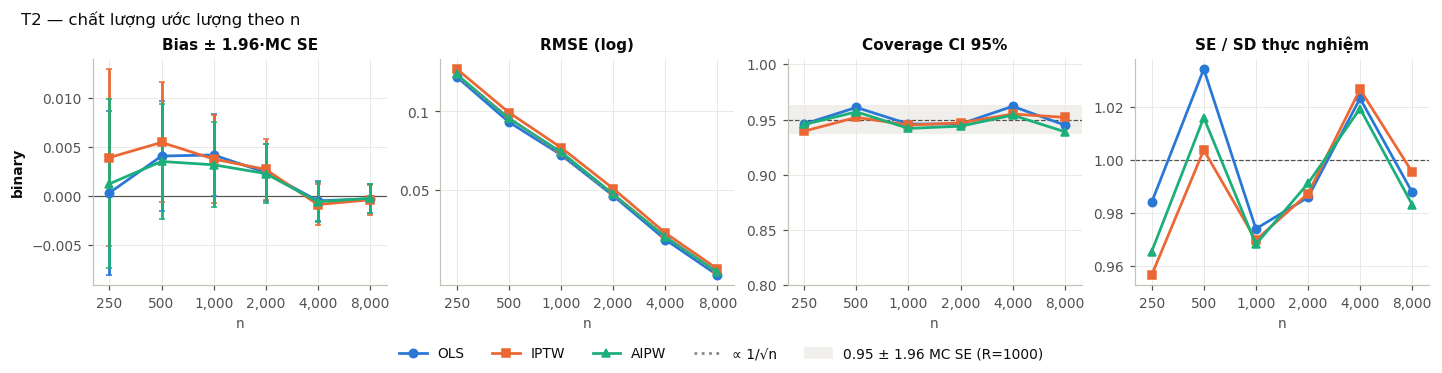

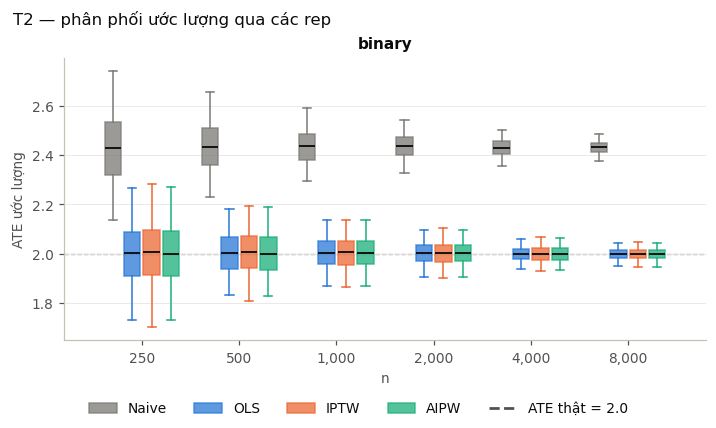

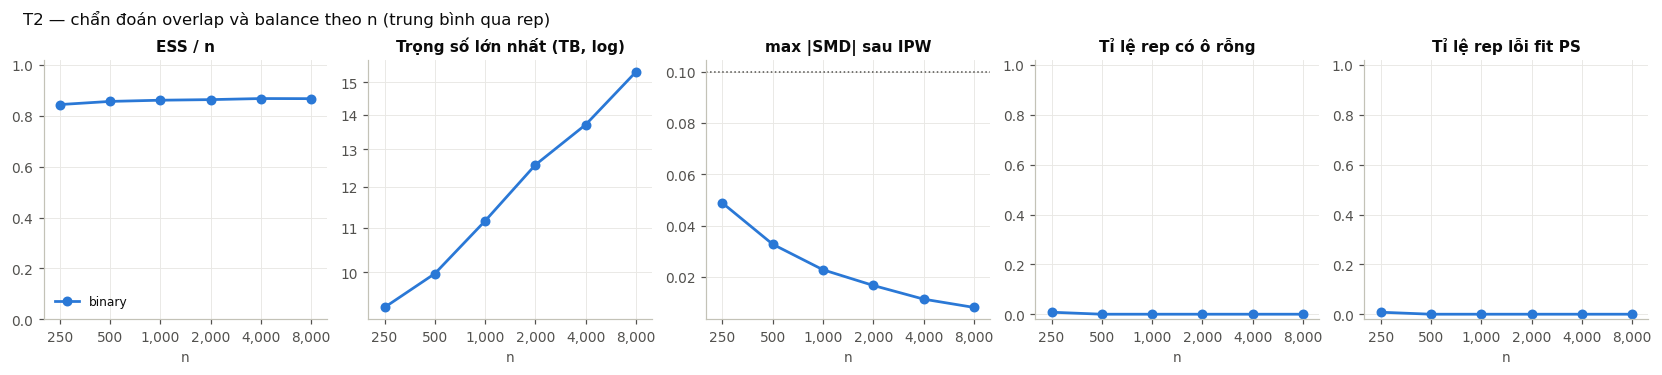

**Giải thích:** Cần đọc đồng thời SE/SD, coverage và số lần có ô rỗng; không suy luận chỉ từ bias.

In [32]:
report_scenario("T2")

### T3a — X2 thứ bậc, hiệu ứng tuyến tính theo mức

**Kỳ vọng:** Integer và dummy cùng gần không chệch; dummy có thể mất một ít hiệu quả.  
**Theo n:** Cả hai mã hóa có RMSE giảm theo 1/√n; chênh lệch hiệu quả của dummy nhỏ.

**Kết quả Monte Carlo** (cột = n)

bias                                    coverage         \
n               250    500    1000   2000   4000   8000     250    500    
integer Naive  0.449  0.455  0.448  0.451  0.450  0.451    0.157  0.014   
        OLS   -0.001  0.006 -0.001  0.001 -0.001 -0.000    0.947  0.951   
        IPTW   0.004  0.007 -0.000  0.001 -0.001  0.000    0.945  0.950   
        AIPW   0.001  0.006 -0.000  0.001 -0.001  0.000    0.947  0.949   
dummy   Naive  0.449  0.455  0.448  0.451  0.450  0.451    0.157  0.014   
        OLS   -0.001  0.006 -0.000  0.001 -0.001 -0.000    0.949  0.954   
        IPTW   0.004  0.007 -0.001  0.001 -0.001  0.000    0.938  0.953   
        AIPW   0.002  0.006 -0.001  0.001 -0.001  0.000    0.940  0.952   

                                           
n               1000   2000   4000   8000  
integer Naive  0.000  0.000  0.000  0.000  
        OLS    0.956  0.949  0.943  0.950  
        IPTW   0.955  0.946  0.947  0.953  
        AIPW   0.958  0.943  0.945  0.951  
dummy   Naive  0.000  0.000  0.000  0.000  
        OLS    0.956  0.950  0.945  0.950  
        IPTW   0.955  0.942  0.943  0.953  
        AIPW   0.958  0.943  0.947  0.953

**Tỉ lệ rep thất bại** (chỉ số trên tính trên rep thành công)

n               250   500   1000  2000  4000  8000
integer Naive  0.000   0.0   0.0   0.0   0.0   0.0
        OLS    0.000   0.0   0.0   0.0   0.0   0.0
        IPTW   0.000   0.0   0.0   0.0   0.0   0.0
        AIPW   0.000   0.0   0.0   0.0   0.0   0.0
dummy   Naive  0.000   0.0   0.0   0.0   0.0   0.0
        OLS    0.000   0.0   0.0   0.0   0.0   0.0
        IPTW   0.002   0.0   0.0   0.0   0.0   0.0
        AIPW   0.002   0.0   0.0   0.0   0.0   0.0

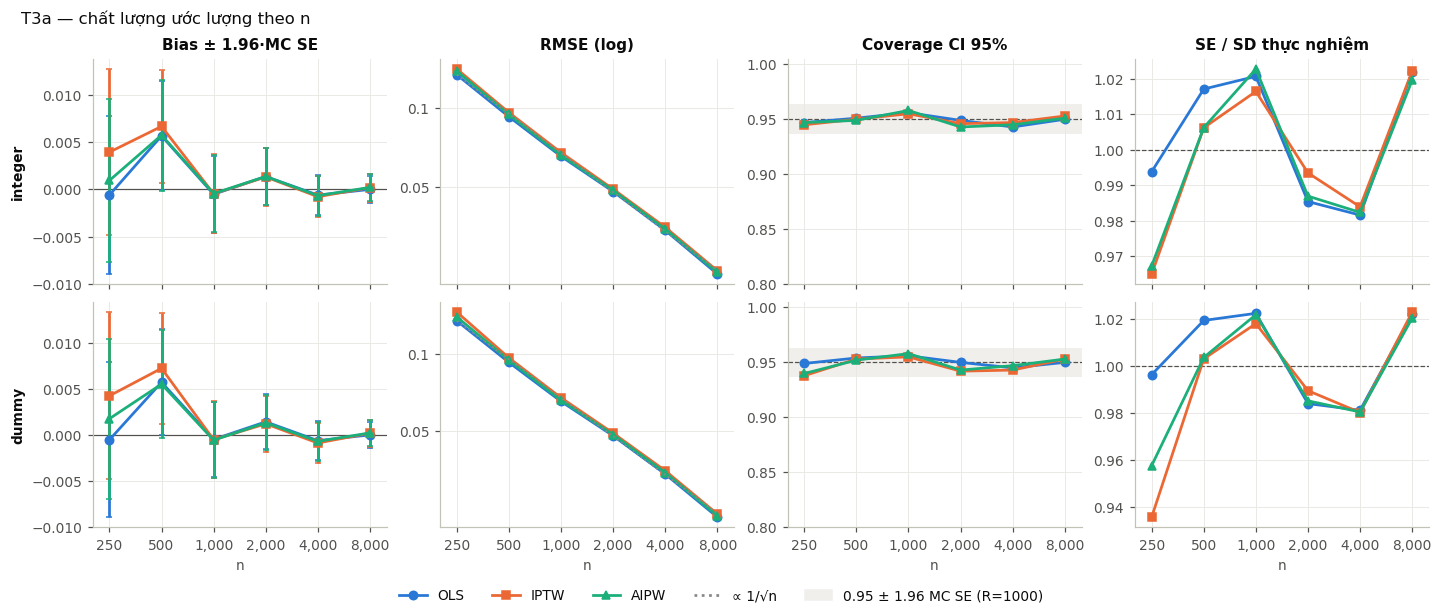

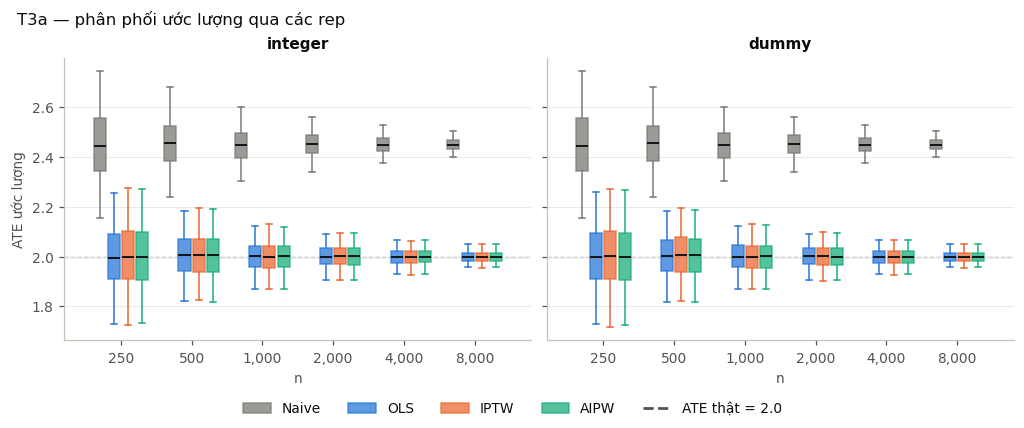

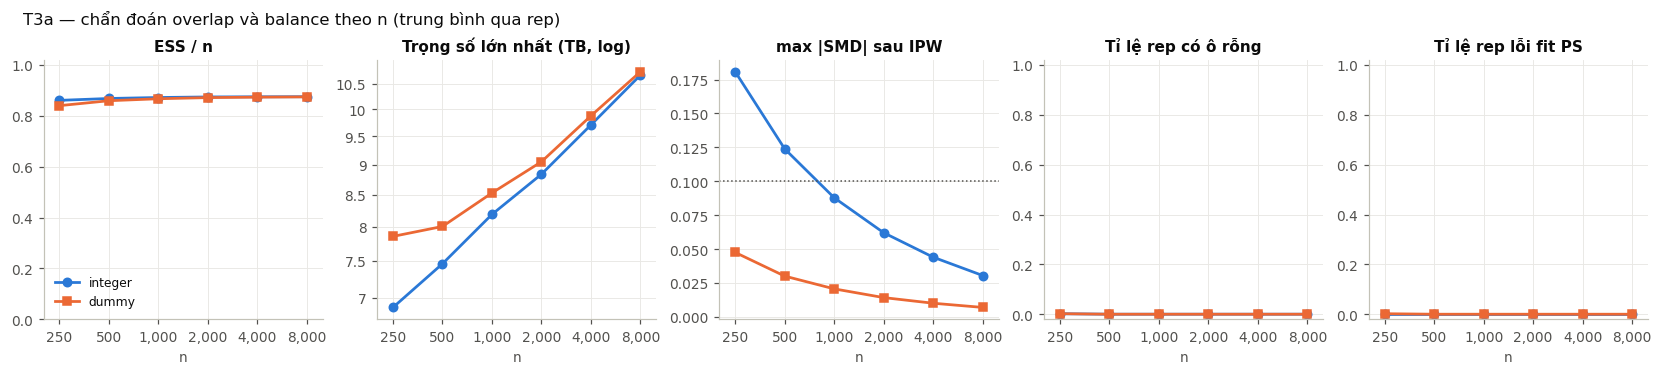

**Giải thích:** Hiệu ứng tuyến tính theo mức nên integer đã đủ; dummy dùng thêm ba tham số.

In [33]:
report_scenario("T3a")

### T3b — X2 thứ bậc, hiệu ứng phi tuyến theo mức

**Kỳ vọng:** Integer chệch; dummy gần không chệch.  
**Theo n:** Bias của integer không giảm theo n, CI hẹp lại nên coverage giảm khi n tăng; dummy giữ coverage gần 0.95.

**Kết quả Monte Carlo** (cột = n)

bias                                    coverage         \
n               250    500    1000   2000   4000   8000     250    500    
integer Naive  0.457  0.454  0.449  0.449  0.451  0.448    0.145  0.014   
        OLS    0.175  0.176  0.171  0.171  0.171  0.169    0.788  0.573   
        IPTW   0.179  0.179  0.174  0.173  0.173  0.172    0.774  0.571   
        AIPW   0.182  0.182  0.177  0.176  0.176  0.174    0.770  0.566   
dummy   Naive  0.457  0.454  0.449  0.449  0.451  0.448    0.145  0.014   
        OLS    0.004  0.004  0.002  0.001 -0.000 -0.001    0.953  0.947   
        IPTW   0.008  0.005  0.002  0.001 -0.001 -0.002    0.949  0.948   
        AIPW   0.005  0.004  0.002  0.001 -0.000 -0.001    0.950  0.946   

                                           
n               1000   2000   4000   8000  
integer Naive  0.000  0.000  0.000  0.000  
        OLS    0.330  0.068  0.003  0.000  
        IPTW   0.322  0.061  0.002  0.000  
        AIPW   0.308  0.052  0.003  0.000  
dummy   Naive  0.000  0.000  0.000  0.000  
        OLS    0.948  0.952  0.950  0.945  
        IPTW   0.944  0.952  0.945  0.940  
        AIPW   0.945  0.957  0.950  0.948

**Tỉ lệ rep thất bại** (chỉ số trên tính trên rep thành công)

n               250   500   1000  2000  4000  8000
integer Naive  0.000   0.0   0.0   0.0   0.0   0.0
        OLS    0.000   0.0   0.0   0.0   0.0   0.0
        IPTW   0.000   0.0   0.0   0.0   0.0   0.0
        AIPW   0.000   0.0   0.0   0.0   0.0   0.0
dummy   Naive  0.000   0.0   0.0   0.0   0.0   0.0
        OLS    0.000   0.0   0.0   0.0   0.0   0.0
        IPTW   0.001   0.0   0.0   0.0   0.0   0.0
        AIPW   0.001   0.0   0.0   0.0   0.0   0.0

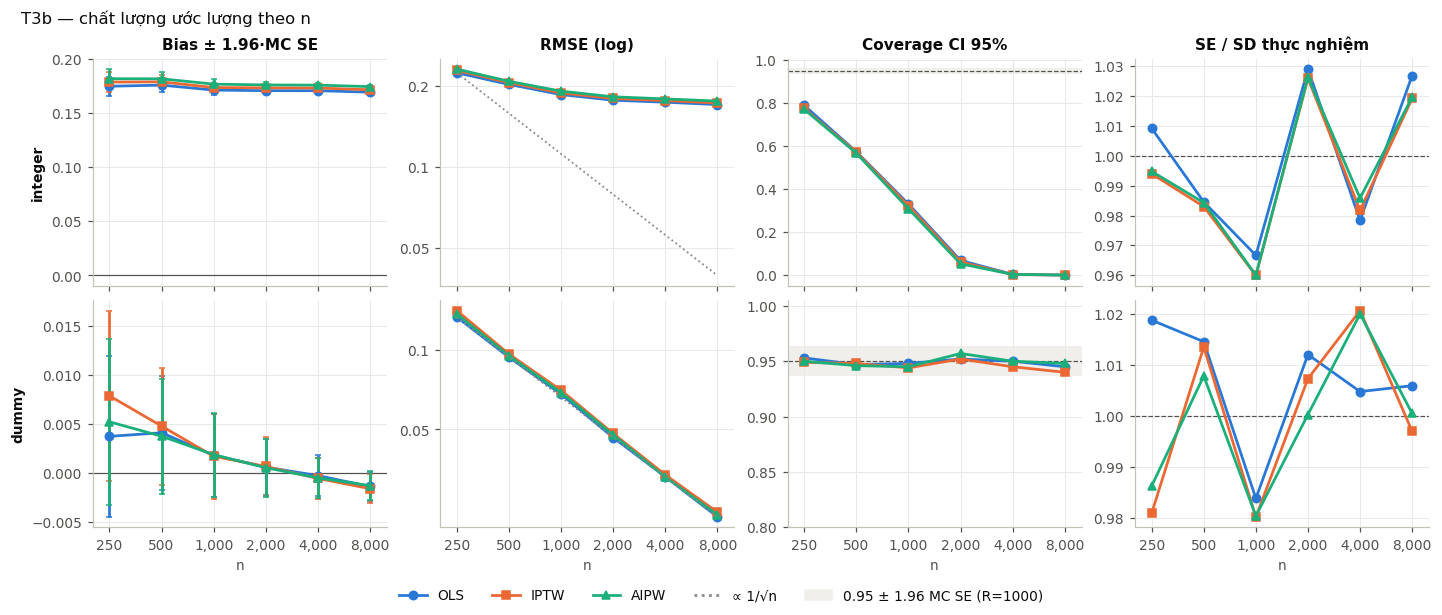

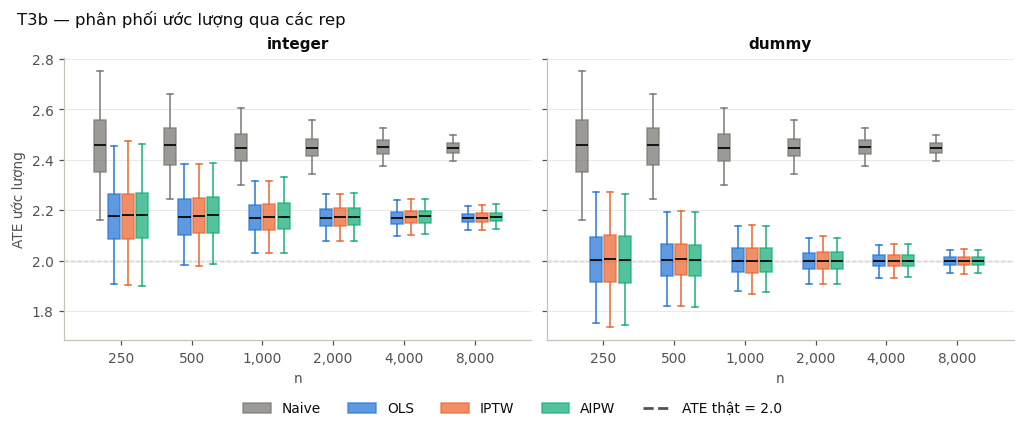

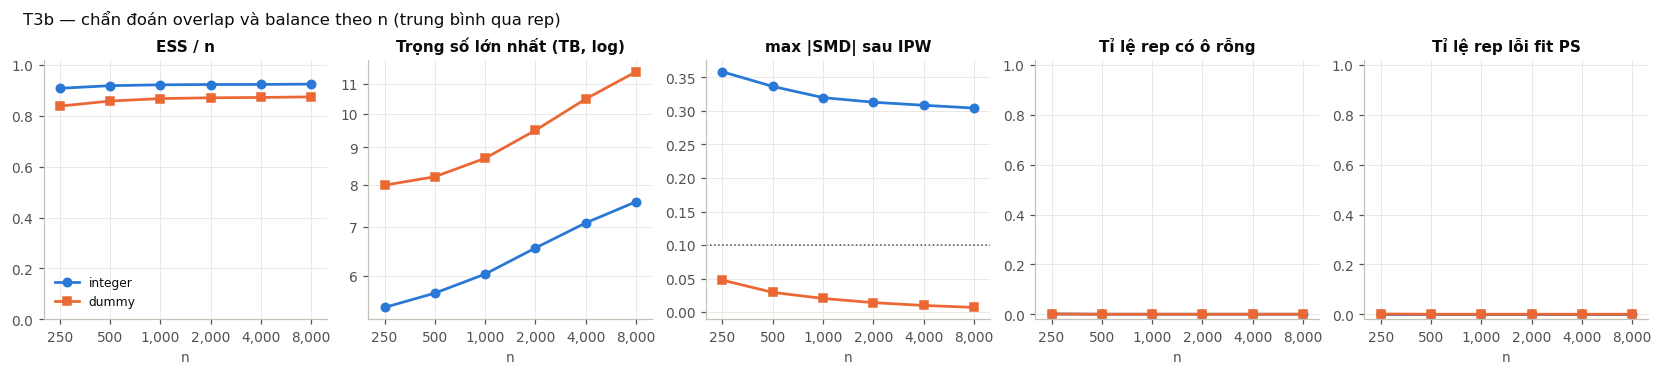

**Giải thích:** Cả PS và outcome dùng integer đều sai dạng; double robustness không cứu khi cả hai sai.

In [34]:
report_scenario("T3b")

### T4 — X2 danh nghĩa

**Kỳ vọng:** Label encoding sai dạng so với dummy; dấu và độ lớn bias phụ thuộc g/h.  
**Theo n:** Như T3b: bias của label giữ nguyên theo n nên coverage giảm khi n tăng.

**Kết quả Monte Carlo** (cột = n)

bias                                    coverage                \
n             250    500    1000   2000   4000   8000     250    500    1000   
dummy Naive  0.399  0.395  0.398  0.395  0.396  0.396    0.258  0.053  0.002   
      OLS    0.006  0.002  0.003 -0.000  0.001  0.000    0.941  0.958  0.953   
      IPTW   0.006  0.003  0.003  0.001  0.002  0.000    0.937  0.957  0.949   
      AIPW   0.004  0.002  0.003  0.000  0.001  0.000    0.942  0.960  0.951   
label Naive  0.399  0.395  0.398  0.395  0.396  0.396    0.258  0.053  0.002   
      OLS    0.196  0.193  0.195  0.190  0.193  0.192    0.729  0.515  0.225   
      IPTW   0.195  0.193  0.195  0.191  0.193  0.192    0.725  0.512  0.232   
      AIPW   0.195  0.193  0.195  0.190  0.193  0.192    0.722  0.513  0.224   

                                  
n             2000   4000   8000  
dummy Naive  0.000  0.000  0.000  
      OLS    0.954  0.951  0.952  
      IPTW   0.945  0.949  0.948  
      AIPW   0.948  0.957  0.957  
label Naive  0.000  0.000  0.000  
      OLS    0.035  0.000  0.000  
      IPTW   0.035  0.000  0.000  
      AIPW   0.037  0.000  0.000

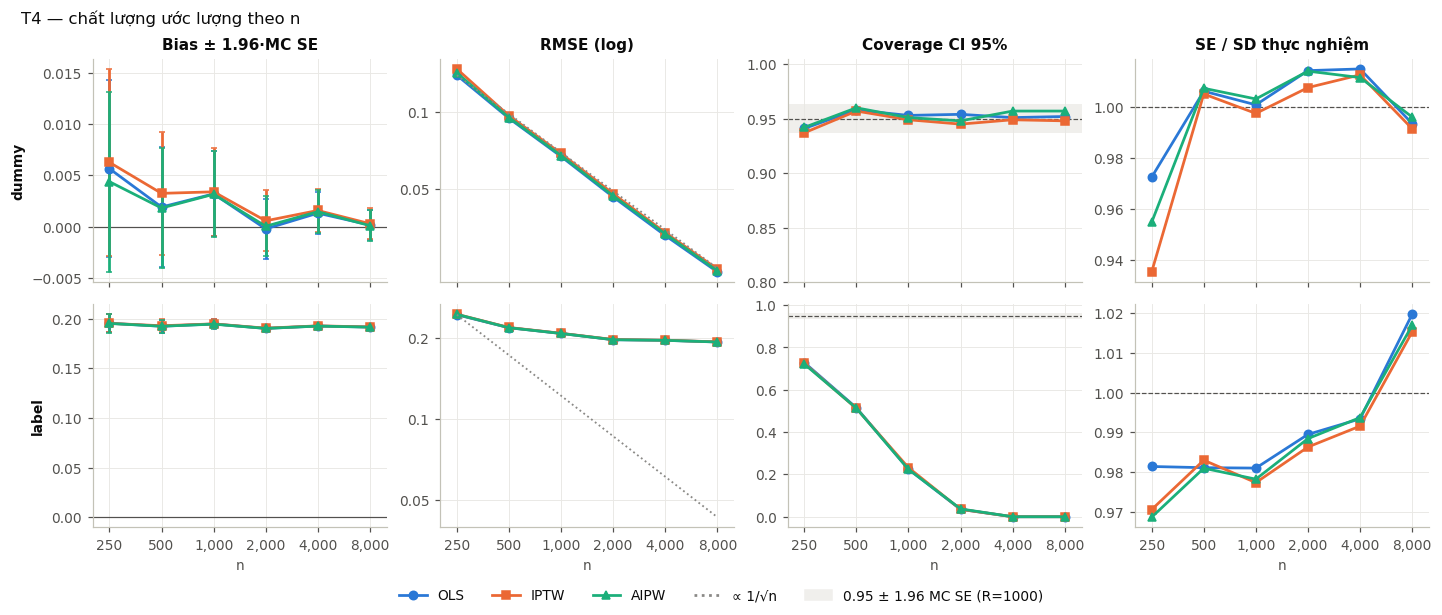

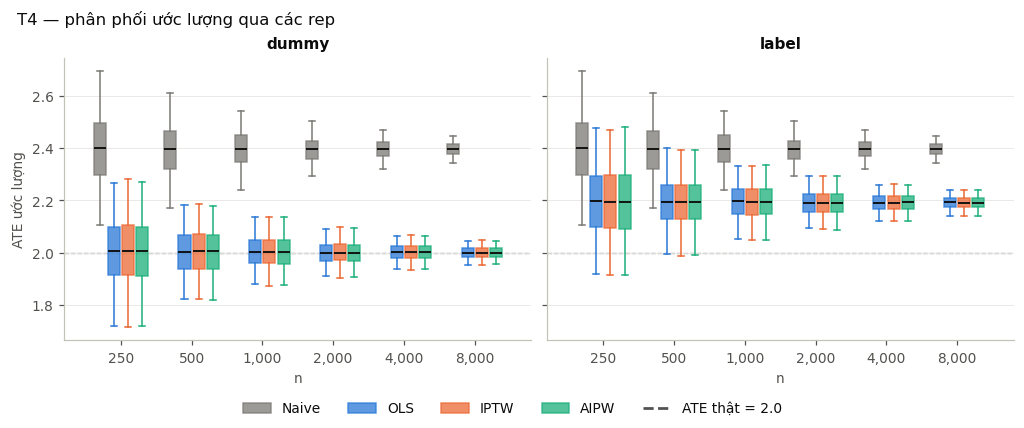

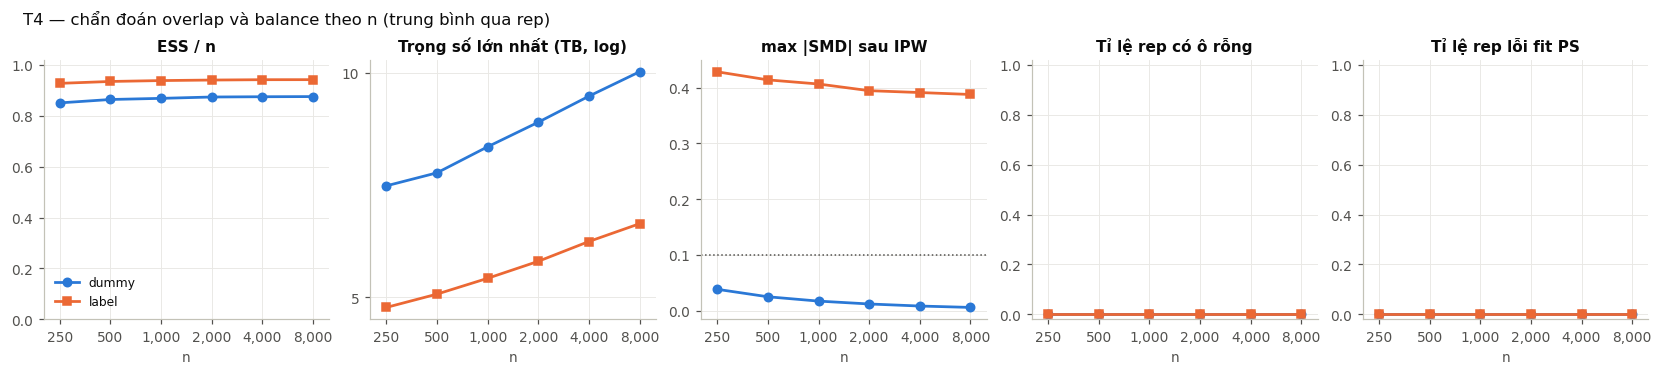

**Giải thích:** Hiệu ứng PS và outcome khác nhau; thứ tự nhãn không biểu diễn vector hiệu ứng theo mức.

In [35]:
report_scenario("T4")

### T5 — Mức hiếm có overlap kém

**Kỳ vọng:** Trọng số cực đoan, ESS thấp, có thể có ô control rỗng ở mức hiếm.  
**Theo n:** n nhỏ: mức hiếm có rất ít control nên nhiều rep có ô rỗng hoặc fit thất bại; tăng n giảm tỉ lệ lỗi nhưng ESS/n vẫn thấp vì overlap kém là đặc tính của DGP.

**Kết quả Monte Carlo** (cột = n)

bias                                    coverage                \
n             250    500    1000   2000   4000   8000     250    500    1000   
dummy Naive  0.422  0.430  0.434  0.434  0.430  0.432    0.208  0.026  0.000   
      OLS   -0.007 -0.000 -0.000 -0.001 -0.003 -0.000    0.941  0.946  0.942   
      IPTW   0.006  0.000  0.007 -0.000  0.001  0.001    0.866  0.804  0.814   
      AIPW   0.002 -0.008  0.001 -0.003 -0.002  0.001    0.896  0.840  0.829   

                                  
n             2000   4000   8000  
dummy Naive  0.000  0.000  0.000  
      OLS    0.939  0.951  0.958  
      IPTW   0.854  0.892  0.906  
      AIPW   0.883  0.919  0.925

**Tỉ lệ rep thất bại** (chỉ số trên tính trên rep thành công)

n             250    500   1000   2000  4000  8000
dummy Naive  0.000  0.000  0.00  0.000   0.0   0.0
      OLS    0.000  0.000  0.00  0.000   0.0   0.0
      IPTW   0.568  0.376  0.13  0.028   0.0   0.0
      AIPW   0.568  0.376  0.13  0.028   0.0   0.0

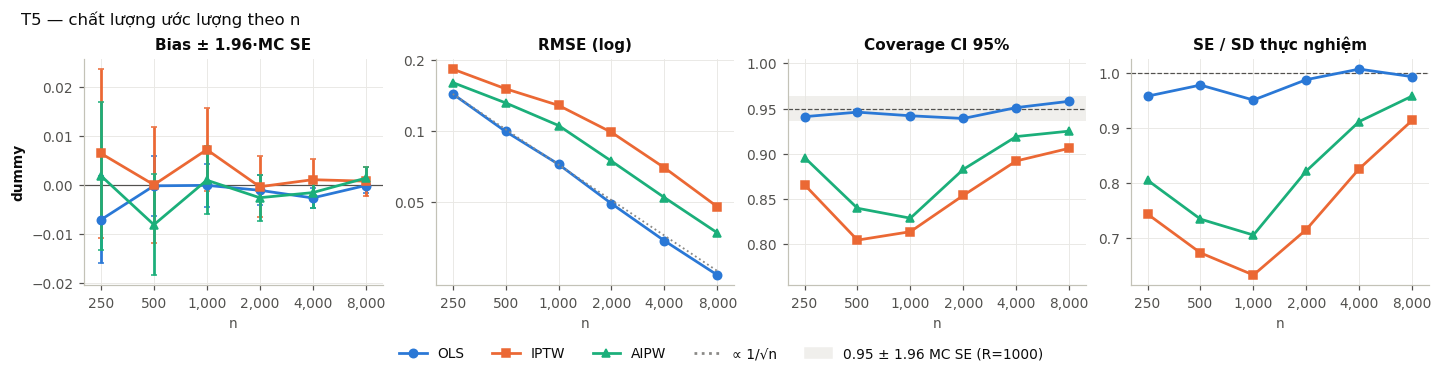

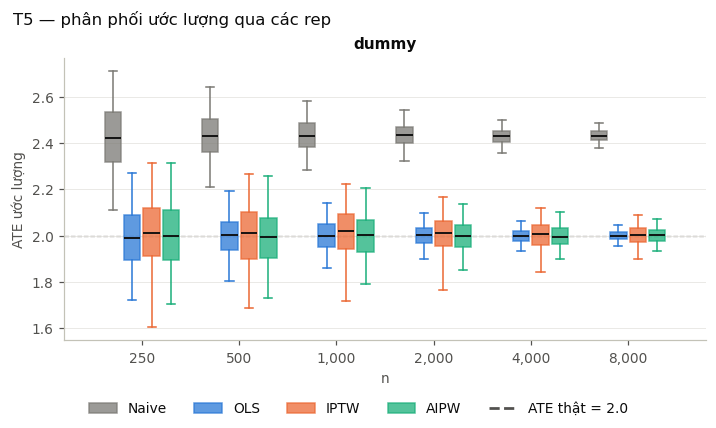

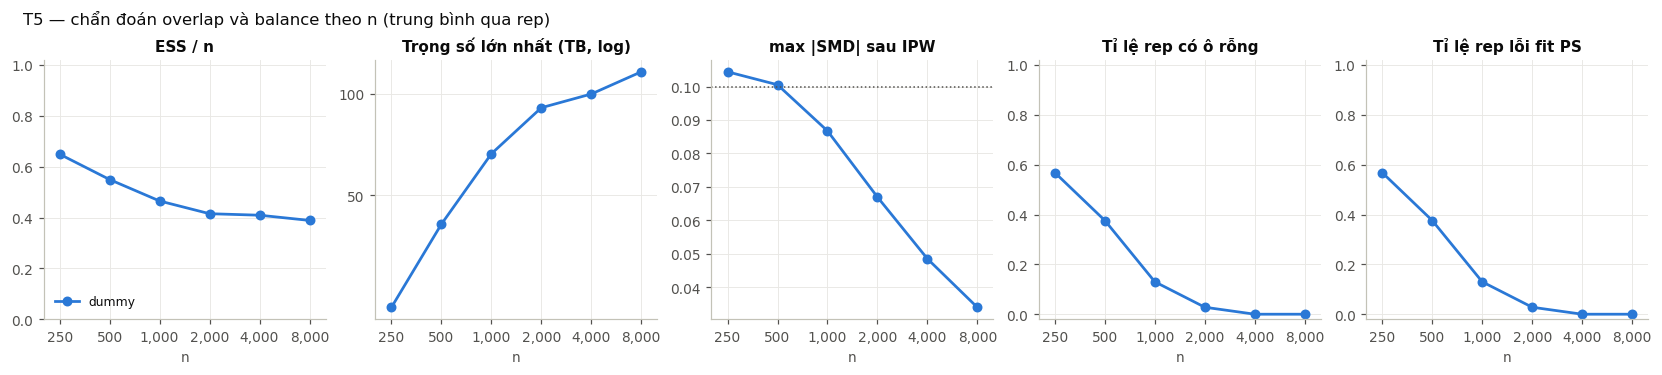

**Giải thích:** T5 cố ý phá quy tắc giữ Var(g)=0.25 để tạo marginal e≈0.98 trong mức hiếm. Fit thất bại vẫn lưu một dòng; chỉ số chất lượng tính trên các lần thành công. Vì vậy ở n nhỏ, ESS/n và trọng số lớn nhất chỉ phản ánh các rep fit được PS (có chọn lọc), nên trông tốt hơn n lớn; cần đọc cùng tỉ lệ lỗi fit.

In [36]:
report_scenario("T5")

### T6 — Rời rạc hóa X2 liên tục

**Kỳ vọng:** Bias còn sót giảm khi tăng số nhóm; tăng n không xóa bias do rời rạc hóa.  
**Theo n:** Bias của các cách chia nhóm gần như không đổi theo n, nên coverage giảm dần khi n tăng, rõ nhất khi ít nhóm.

**Kết quả Monte Carlo** (cột = n)

bias                                    coverage         \
n                  250    500    1000   2000   4000   8000     250    500    
continuous Naive  0.451  0.448  0.446  0.448  0.451  0.451    0.164  0.014   
           OLS    0.002 -0.002 -0.003  0.000  0.001  0.002    0.961  0.947   
           IPTW   0.005 -0.001 -0.003  0.001  0.001  0.002    0.951  0.948   
           AIPW   0.004 -0.002 -0.003 -0.000  0.001  0.002    0.953  0.949   
omit_X2    Naive  0.451  0.448  0.446  0.448  0.451  0.451    0.164  0.014   
           OLS    0.240  0.233  0.233  0.236  0.237  0.239    0.598  0.386   
           IPTW   0.240  0.233  0.233  0.236  0.238  0.239    0.606  0.383   
           AIPW   0.240  0.233  0.233  0.236  0.238  0.239    0.606  0.382   
binned_2   Naive  0.451  0.448  0.446  0.448  0.451  0.451    0.164  0.014   
           OLS    0.088  0.085  0.083  0.086  0.087  0.089    0.895  0.864   
           IPTW   0.089  0.085  0.084  0.086  0.087  0.089    0.893  0.857   
           AIPW   0.089  0.085  0.083  0.086  0.087  0.089    0.897  0.864   
binned_3   Naive  0.451  0.448  0.446  0.448  0.451  0.451    0.164  0.014   
           OLS    0.051  0.047  0.046  0.049  0.049  0.051    0.936  0.923   
           IPTW   0.052  0.048  0.047  0.049  0.050  0.052    0.932  0.918   
           AIPW   0.052  0.048  0.046  0.049  0.050  0.051    0.933  0.922   
binned_5   Naive  0.451  0.448  0.446  0.448  0.451  0.451    0.164  0.014   
           OLS    0.025  0.022  0.020  0.023  0.024  0.026    0.948  0.945   
           IPTW   0.027  0.023  0.021  0.024  0.025  0.027    0.938  0.945   
           AIPW   0.028  0.023  0.020  0.024  0.025  0.027    0.944  0.944   
binned_10  Naive  0.451  0.448  0.446  0.448  0.451  0.451    0.164  0.014   
           OLS    0.011  0.008  0.006  0.009  0.010  0.011    0.957  0.949   
           IPTW   0.014  0.009  0.006  0.010  0.011  0.012    0.946  0.949   
           AIPW   0.014  0.008  0.006  0.010  0.010  0.012    0.943  0.947   

                                              
n                  1000   2000   4000   8000  
continuous Naive  0.000  0.000  0.000  0.000  
           OLS    0.952  0.945  0.941  0.939  
           IPTW   0.956  0.951  0.949  0.941  
           AIPW   0.951  0.951  0.948  0.941  
omit_X2    Naive  0.000  0.000  0.000  0.000  
           OLS    0.108  0.004  0.000  0.000  
           IPTW   0.110  0.004  0.000  0.000  
           AIPW   0.108  0.004  0.000  0.000  
binned_2   Naive  0.000  0.000  0.000  0.000  
           OLS    0.777  0.581  0.271  0.050  
           IPTW   0.792  0.584  0.290  0.060  
           AIPW   0.786  0.588  0.280  0.056  
binned_3   Naive  0.000  0.000  0.000  0.000  
           OLS    0.901  0.807  0.688  0.441  
           IPTW   0.903  0.813  0.680  0.444  
           AIPW   0.898  0.812  0.682  0.441  
binned_5   Naive  0.000  0.000  0.000  0.000  
           OLS    0.936  0.928  0.893  0.807  
           IPTW   0.941  0.923  0.887  0.812  
           AIPW   0.940  0.928  0.889  0.809  
binned_10  Naive  0.000  0.000  0.000  0.000  
           OLS    0.954  0.942  0.934  0.905  
           IPTW   0.948  0.942  0.943  0.898  
           AIPW   0.947  0.945  0.936  0.900

**Tỉ lệ rep thất bại** (chỉ số trên tính trên rep thành công)

n                  250   500   1000  2000  4000  8000
continuous Naive  0.000   0.0   0.0   0.0   0.0   0.0
           OLS    0.000   0.0   0.0   0.0   0.0   0.0
           IPTW   0.000   0.0   0.0   0.0   0.0   0.0
           AIPW   0.000   0.0   0.0   0.0   0.0   0.0
omit_X2    Naive  0.000   0.0   0.0   0.0   0.0   0.0
           OLS    0.000   0.0   0.0   0.0   0.0   0.0
           IPTW   0.000   0.0   0.0   0.0   0.0   0.0
           AIPW   0.000   0.0   0.0   0.0   0.0   0.0
binned_2   Naive  0.000   0.0   0.0   0.0   0.0   0.0
           OLS    0.000   0.0   0.0   0.0   0.0   0.0
           IPTW   0.000   0.0   0.0   0.0   0.0   0.0
           AIPW   0.000   0.0   0.0   0.0   0.0   0.0
binned_3   Naive  0.000   0.0   0.0   0.0   0.0   0.0
           OLS    0.000   0.0   0.0   0.0   0.0   0.0
           IPTW   0.000   0.0   0.0   0.0   0.0   0.0
           AIPW   0.000   0.0   0.0   0.0   0.0   0.0
binned_5   Naive  0.000   0.0   0.0   0.0   0.0   0.0
           OLS    0.000   0.0   0.0   0.0   0.0   0.0
           IPTW   0.000   0.0   0.0   0.0   0.0   0.0
           AIPW   0.000   0.0   0.0   0.0   0.0   0.0
binned_10  Naive  0.000   0.0   0.0   0.0   0.0   0.0
           OLS    0.000   0.0   0.0   0.0   0.0   0.0
           IPTW   0.001   0.0   0.0   0.0   0.0   0.0
           AIPW   0.001   0.0   0.0   0.0   0.0   0.0

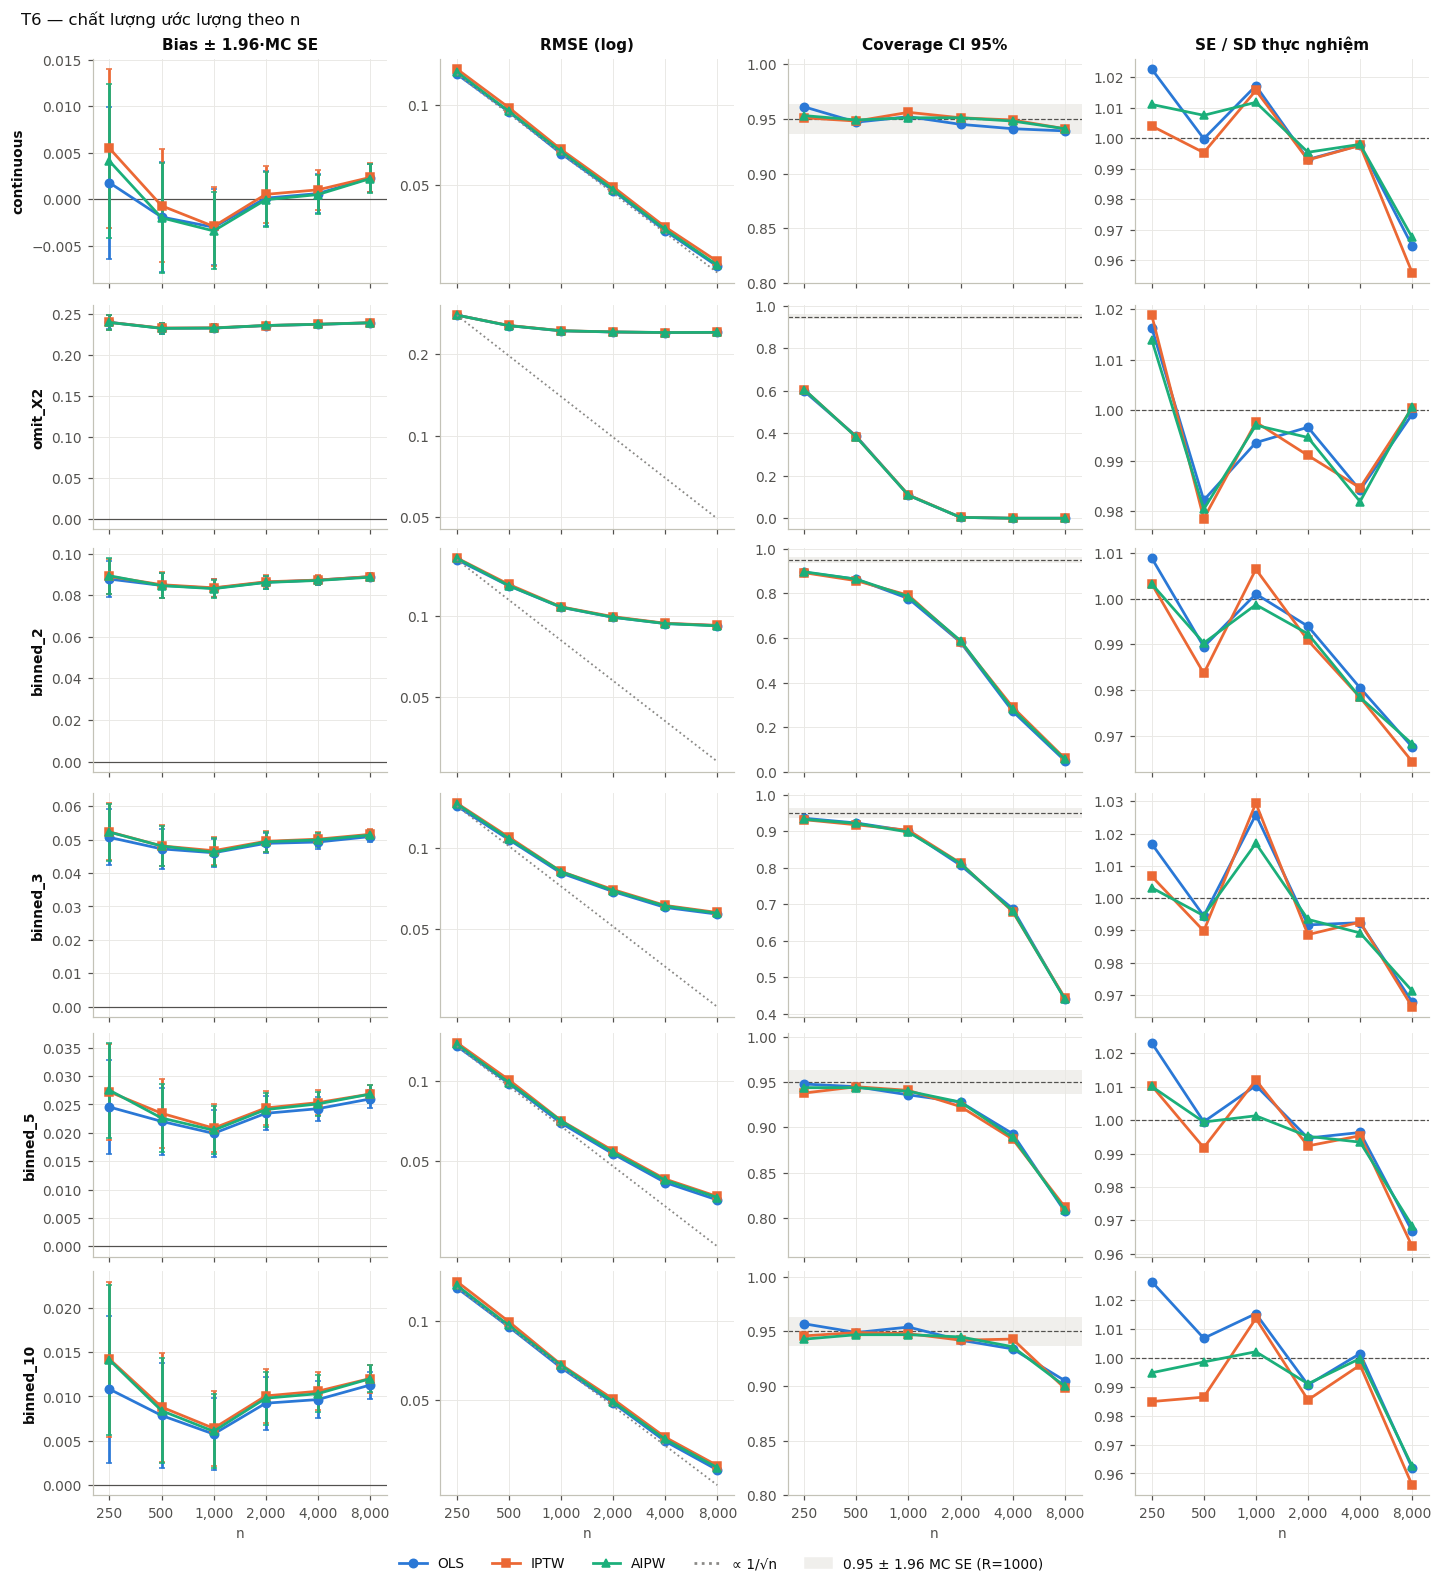

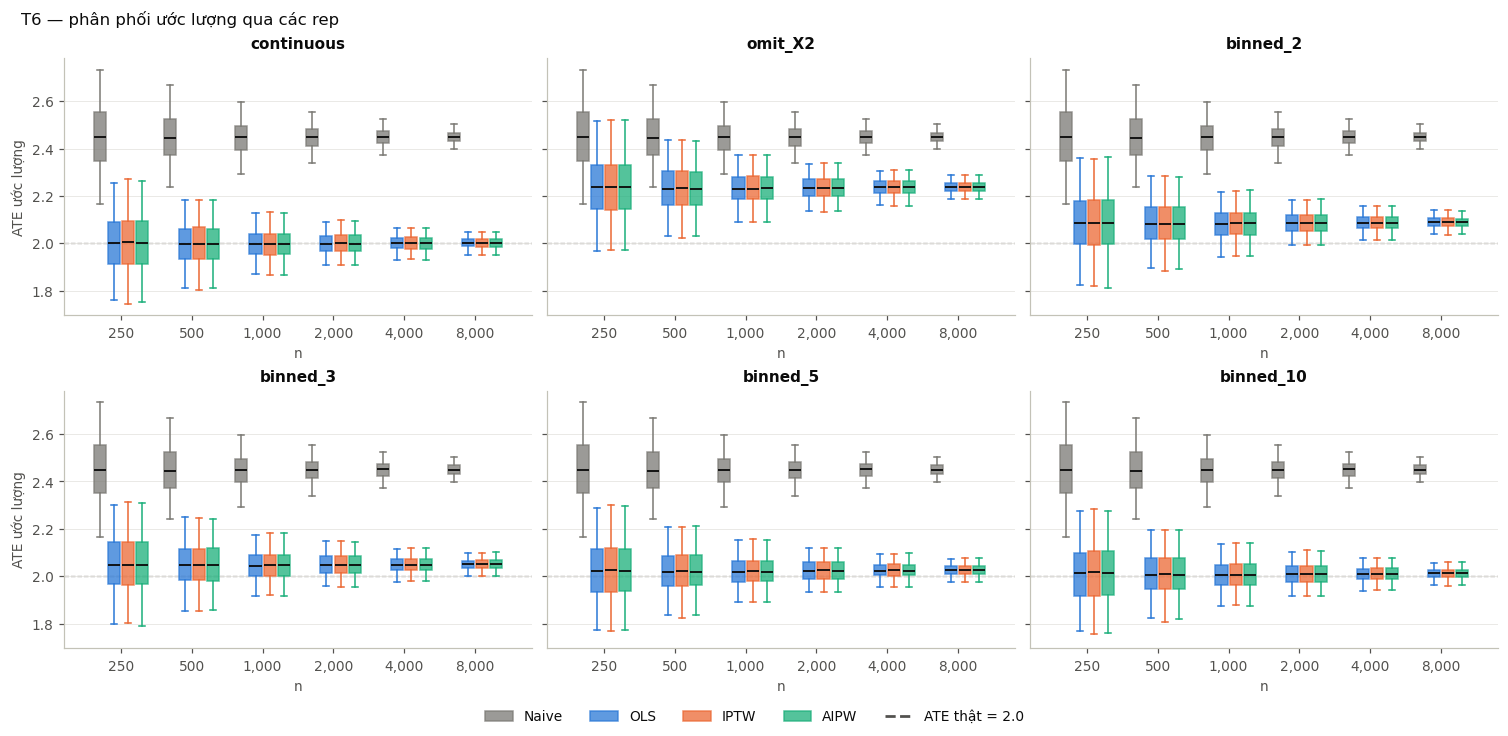

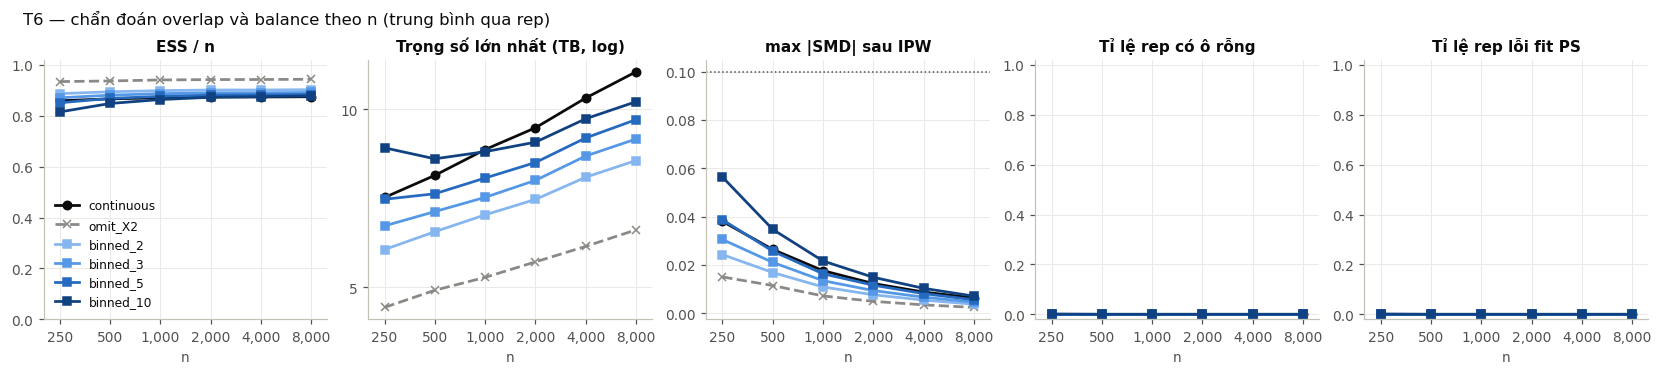

**Giải thích:** DGP dùng X2 liên tục, analysis dùng nhóm phân vị. CI hẹp dần khi n tăng khiến coverage giảm nếu bias còn sót. So sánh hai mốc continuous và omit_X2.

In [37]:
report_scenario("T6")

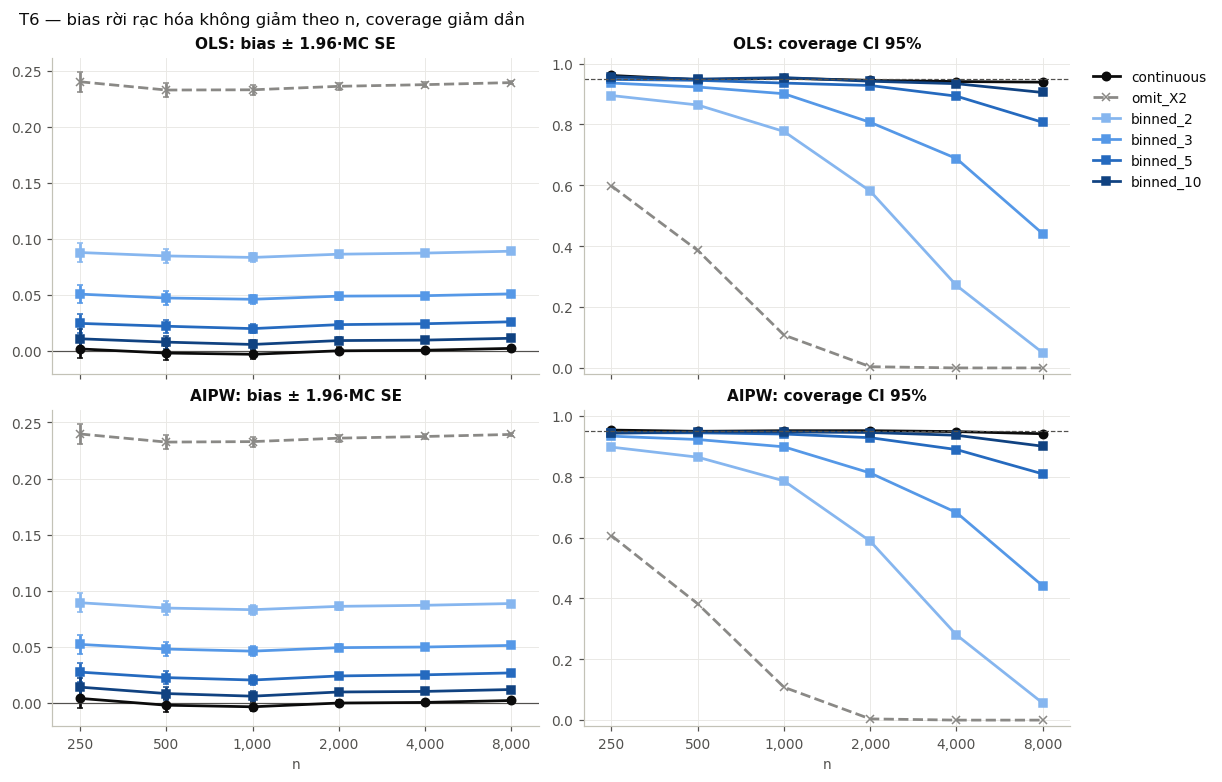

In [38]:
# T6: đặt mọi cách chia nhóm trên cùng trục để thấy bias còn sót theo số nhóm.
fig = plot_t6_binning(summary)
fig.savefig(RESULT_DIR / "T6_bias_coverage.png", bbox_inches="tight")
save_fig(fig, "T6_binning")

## 14. Kết luận từ lần chạy
Kết luận dùng các số của OLS trên toàn lưới n (không còn cố định n=2000) và được ghi ra `results/part_A_conclusions.md`.

In [39]:
KEY_CASES = [("T0", "continuous"), ("T1", "binary"), ("T2", "binary"),
             ("T3a", "integer"), ("T3a", "dummy"), ("T3b", "integer"), ("T3b", "dummy"),
             ("T4", "label"), ("T4", "dummy"), ("T5", "dummy"),
             ("T6", "omit_X2"), ("T6", "binned_2"), ("T6", "binned_5"),
             ("T6", "binned_10"), ("T6", "continuous")]


def key_table(summary, value, fmt, method="OLS"):
    """Bảng markdown kịch bản·phân tích × n; ô trống (n không chạy) ghi '—'."""
    table = (summary[summary.method.eq(method)]
             .pivot_table(index=["scenario", "analysis"], columns="n", values=value)
             .reindex(KEY_CASES))
    table.index = [f"{s} · {a}" for s, a in table.index]
    table.columns = [f"n={n:,}" for n in table.columns]
    text = table.apply(lambda col: col.map(lambda v: "—" if pd.isna(v) else fmt.format(v)))
    return text.to_markdown(colalign=("left",) + ("right",)*text.shape[1], disable_numparse=True)


def conclude_type(summary):
    bias, cov = key_table(summary, "bias", "{:+.3f}"), key_table(summary, "coverage", "{:.3f}")
    ols = summary[summary.method.eq("OLS")].set_index(["scenario", "analysis", "n"])
    n_lo, n_hi = min(N_VALUES), max(N_VALUES)
    t6_n = n_grid("T6")

    def drift(s, a, value, ns=(n_lo, n_hi)):
        fmt = "{:+.3f}" if value == "bias" else "{:.3f}"
        return f"{fmt.format(ols.loc[(s, a, ns[0]), value])} → {fmt.format(ols.loc[(s, a, ns[-1]), value])}"

    rates = summary.set_index(["scenario", "analysis", "method", "n"]).failure_rate

    def drift_rate(s, a, method):
        return f"{rates.loc[(s, a, method, n_lo)]:.0%} → {rates.loc[(s, a, method, n_hi)]:.0%}"

    lines = [
        "## Kết luận phần A",
        f"Lưới n = {', '.join(f'{n:,}' for n in N_VALUES)}, "
        f"R={R}. Số dưới đây là của OLS; IPTW/AIPW xem mục 12–13.",
        "**Bias OLS theo n**", bias,
        "**Coverage CI 95% của OLS theo n**", cov,
        f"- Mã hóa đúng dạng (T0, T1, T3a, dummy ở T3b/T4) có bias nằm trong vài MC SE ở mọi n; "
        f"RMSE giảm theo n. Ví dụ T0: bias {drift('T0', 'continuous', 'bias')} (n={n_lo:,} → {n_hi:,}).",
        f"- Mã hóa sai dạng giữ bias gần như cố định khi n tăng: T3b integer {drift('T3b', 'integer', 'bias')}, "
        f"T4 label {drift('T4', 'label', 'bias')}. Vì CI hẹp lại, coverage giảm: "
        f"T3b integer {drift('T3b', 'integer', 'coverage')}, T4 label {drift('T4', 'label', 'coverage')}.",
        f"- T6: bias của binned_5 {drift('T6', 'binned_5', 'bias', t6_n)}, coverage "
        f"{drift('T6', 'binned_5', 'coverage', t6_n)} (n={t6_n[0]:,} → {t6_n[-1]:,}). "
        "Chia nhiều nhóm giữ được nhiều thông tin hơn; tăng n không khôi phục thông tin liên tục bị mất.",
        f"- T5 (AIPW): tỉ lệ rep thất bại {drift_rate('T5', 'dummy', 'AIPW')} (n={n_lo:,} → {n_hi:,}), "
        "do mức hiếm có quá ít control nên logistic không hội tụ hoặc ô rỗng. "
        "Overlap kém không biến mất khi tăng n; nó chỉ chuyển từ lỗi fit sang trọng số lớn.",
        "- Coverage và SE/SD cần đọc cùng MC SE và failure rate, đặc biệt T5 ở n nhỏ. "
        f"Kết quả đang dùng R={R}; R={R_FULL} là mức chạy đầy đủ theo thiết kế.",
    ]
    return "\n\n".join(lines)


conclusion = conclude_type(summary)
display(Markdown(conclusion))
(RESULT_DIR / "part_A_conclusions.md").write_text(conclusion, encoding="utf-8")

## Kết luận phần A

Lưới n = 250, 500, 1,000, 2,000, 4,000, 8,000, R=1000. Số dưới đây là của OLS; IPTW/AIPW xem mục 12–13.

**Bias OLS theo n**

|                 |   n=250 |   n=500 |   n=1,000 |   n=2,000 |   n=4,000 |   n=8,000 |
|:----------------|--------:|--------:|----------:|----------:|----------:|----------:|
| T0 · continuous |  +0.005 |  +0.000 |    -0.000 |    -0.000 |    +0.001 |    +0.001 |
| T1 · binary     |  -0.004 |  -0.001 |    +0.001 |    +0.001 |    -0.001 |    +0.000 |
| T2 · binary     |  +0.000 |  +0.004 |    +0.004 |    +0.002 |    -0.000 |    -0.000 |
| T3a · integer   |  -0.001 |  +0.006 |    -0.001 |    +0.001 |    -0.001 |    -0.000 |
| T3a · dummy     |  -0.001 |  +0.006 |    -0.000 |    +0.001 |    -0.001 |    -0.000 |
| T3b · integer   |  +0.175 |  +0.176 |    +0.171 |    +0.171 |    +0.171 |    +0.169 |
| T3b · dummy     |  +0.004 |  +0.004 |    +0.002 |    +0.001 |    -0.000 |    -0.001 |
| T4 · label      |  +0.196 |  +0.193 |    +0.195 |    +0.190 |    +0.193 |    +0.192 |
| T4 · dummy      |  +0.006 |  +0.002 |    +0.003 |    -0.000 |    +0.001 |    +0.000 |
| T5 · dummy      |  -0.007 |  -0.000 |    -0.000 |    -0.001 |    -0.003 |    -0.000 |
| T6 · omit_X2    |  +0.240 |  +0.233 |    +0.233 |    +0.236 |    +0.237 |    +0.239 |
| T6 · binned_2   |  +0.088 |  +0.085 |    +0.083 |    +0.086 |    +0.087 |    +0.089 |
| T6 · binned_5   |  +0.025 |  +0.022 |    +0.020 |    +0.023 |    +0.024 |    +0.026 |
| T6 · binned_10  |  +0.011 |  +0.008 |    +0.006 |    +0.009 |    +0.010 |    +0.011 |
| T6 · continuous |  +0.002 |  -0.002 |    -0.003 |    +0.000 |    +0.001 |    +0.002 |

**Coverage CI 95% của OLS theo n**

|                 |   n=250 |   n=500 |   n=1,000 |   n=2,000 |   n=4,000 |   n=8,000 |
|:----------------|--------:|--------:|----------:|----------:|----------:|----------:|
| T0 · continuous |   0.935 |   0.948 |     0.958 |     0.940 |     0.958 |     0.945 |
| T1 · binary     |   0.926 |   0.943 |     0.935 |     0.958 |     0.954 |     0.955 |
| T2 · binary     |   0.946 |   0.961 |     0.946 |     0.946 |     0.962 |     0.945 |
| T3a · integer   |   0.947 |   0.951 |     0.956 |     0.949 |     0.943 |     0.950 |
| T3a · dummy     |   0.949 |   0.954 |     0.956 |     0.950 |     0.945 |     0.950 |
| T3b · integer   |   0.788 |   0.573 |     0.330 |     0.068 |     0.003 |     0.000 |
| T3b · dummy     |   0.953 |   0.947 |     0.948 |     0.952 |     0.950 |     0.945 |
| T4 · label      |   0.729 |   0.515 |     0.225 |     0.035 |     0.000 |     0.000 |
| T4 · dummy      |   0.941 |   0.958 |     0.953 |     0.954 |     0.951 |     0.952 |
| T5 · dummy      |   0.941 |   0.946 |     0.942 |     0.939 |     0.951 |     0.958 |
| T6 · omit_X2    |   0.598 |   0.386 |     0.108 |     0.004 |     0.000 |     0.000 |
| T6 · binned_2   |   0.895 |   0.864 |     0.777 |     0.581 |     0.271 |     0.050 |
| T6 · binned_5   |   0.948 |   0.945 |     0.936 |     0.928 |     0.893 |     0.807 |
| T6 · binned_10  |   0.957 |   0.949 |     0.954 |     0.942 |     0.934 |     0.905 |
| T6 · continuous |   0.961 |   0.947 |     0.952 |     0.945 |     0.941 |     0.939 |

- Mã hóa đúng dạng (T0, T1, T3a, dummy ở T3b/T4) có bias nằm trong vài MC SE ở mọi n; RMSE giảm theo n. Ví dụ T0: bias +0.005 → +0.001 (n=250 → 8,000).

- Mã hóa sai dạng giữ bias gần như cố định khi n tăng: T3b integer +0.175 → +0.169, T4 label +0.196 → +0.192. Vì CI hẹp lại, coverage giảm: T3b integer 0.788 → 0.000, T4 label 0.729 → 0.000.

- T6: bias của binned_5 +0.025 → +0.026, coverage 0.948 → 0.807 (n=250 → 8,000). Chia nhiều nhóm giữ được nhiều thông tin hơn; tăng n không khôi phục thông tin liên tục bị mất.

- T5 (AIPW): tỉ lệ rep thất bại 57% → 0% (n=250 → 8,000), do mức hiếm có quá ít control nên logistic không hội tụ hoặc ô rỗng. Overlap kém không biến mất khi tăng n; nó chỉ chuyển từ lỗi fit sang trọng số lớn.

- Coverage và SE/SD cần đọc cùng MC SE và failure rate, đặc biệt T5 ở n nhỏ. Kết quả đang dùng R=1000; R=1000 là mức chạy đầy đủ theo thiết kế.

4053